<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_QSentryBackdoorDetection_Wang2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSentry: detecting backdoors in a quantum neural network by clustering its measurements, step by step

**Paper.** Shuolei Wang, Zimeng Xiao, Jinjing Shi, Heyuan Shi, Shichao Zhang, Xuelong Li, *QSentry: Backdoor Detection for Quantum Neural Networks via Measurement Clustering*, arXiv:2511.15376 (2025), DOI 10.48550/arXiv.2511.15376.

**What this notebook does.** It rebuilds the whole experiment of the paper on a CPU, without any quantum hardware:

1. downloads MNIST and keeps the digits **1** (source class) and **7** (target class), resized to 16 x 16 pixels;
2. builds the paper's 8-qubit quantum circuit learning (QCL) classifier (amplitude encoding, 8 layers of RX-RZ-RX rotations plus a ring of CNOTs, outputs <Z0>, <Z1> into a softmax) as an **exact state-vector simulator** and checks it against the PennyLane circuit;
3. **plants backdoors** with the paper's four attacks (patch, blend, sinusoidal, QTrojan circuit attack) at poisoning rates of 1 %, 5 % and 10 %, and measures the clean accuracy (CA) and attack success rate (ASR);
4. applies **QSentry**: collect the 8 qubit expectation values <Z_q> of every test input (the "measurement activation matrix"), reduce it with ICA, cluster it with K-means and flag the smallest cluster as the backdoor cluster;
5. compares the detector with the paper's "Raw" baseline (clustering the input itself) and with classical detectors working on the same measurement statistics, and prints the paper's numbers (Tables I and II, Fig. 9) next to the notebook's with a verdict for every claim.

**How to run.** Open in Google Colab, choose a CPU runtime and press *Runtime -> Run all*. With `FAST_MODE = True` the run takes a few minutes; `FAST_MODE = False` follows the larger budgets listed in the configuration cell (the committed outputs say which of the two was executed). MNIST is public: no token is needed.

**What you get at the end.** Trained clean and backdoored QNNs, the circuit drawings, the dataset figures, the detection tables for all attacks and poisoning rates, the paper's figures redrawn from your own runs, and an honest comparison with the numbers published in the paper (spoiler: the backdoors are implanted as described, with high attack success from 5 % poisoning on, but the very high detection scores of the paper are not reproduced; see the critical reading at the end).

## The paper in one page

**Problem.** Quantum neural networks (QNNs) can be backdoored like classical networks: a model that is accurate on clean inputs predicts an attacker-chosen label as soon as a trigger is present. Classical defences need hidden-layer activations or gradients; in a QNN the intermediate quantum state cannot be observed without collapsing it, so the only observable are the final measurement outcomes.

**Decision.** For a trained QNN and a set of test inputs: which inputs carry a trigger (backdoor samples) and which are clean?

**Method (QSentry, Algorithms 1 and 2).**
1. Run every test input through the QNN and record the expectation value of Pauli-Z on each of the Q qubits: a matrix A of size N x Q (Eq. 4-5, 14).
2. Reduce A with a decomposition (ICA, PCA variants) to a matrix V (Eq. 6, 15).
3. Cluster V with K-means (K = 3: clean source class, clean target class, backdoor samples; Eq. 7) and declare the **smallest cluster** to be the backdoor cluster.
4. Quality indicators: silhouette coefficient (SC), relative cluster size (RCS), detection accuracy (DA) and F1 of the backdoor class.

**Data.** MNIST[1,7], images cropped/resized to 16 x 16, amplitude-encoded on 8 qubits. Detection sets of 1000 samples: 500 clean "7", and 500 "1" of which 1 %, 5 % or 10 % carry the trigger (Table II).

**Model.** Quantum circuit learning (QCL): 8 qubits, 8 layers, each layer RX-RZ-RX on every qubit followed by a circular CNOT ring; <Z0>, <Z1> go to a softmax; cross-entropy loss; PennyLane simulator.

**Attacks.** (a) patch trigger, (b) blend trigger (sigma = 1.5, lambda = 0.3), (c) sinusoidal trigger (amplitude 0.2, frequency 1), (d) QTrojan circuit attack (extra RY(theta) gates after the encoding), with theta = 2 arccos |<psi0|psi1>|; poisoning rates 1 %, 5 %, 10 %; 3 to 5 repetitions averaged.

**Claims to check.**
* CA stays high while ASR rises with the poisoning rate and stabilises at a high level (Figs. 7-8, no numbers in the text).
* Table I: QSentry reaches DA 98.7-99.8 % and F1 71.4-97.1 %; the abstract's headline is a mean F1 over the four attacks of **75.8 %, 85.7 %, 93.2 %** at 1 %, 5 %, 10 % poisoning.
* QSentry beats the Raw baseline (clustering the raw pixels) in every cell of Table I.
* Table II: the predicted backdoor cluster is within a few samples of the true size (50 true -> 53-63 predicted at 10 %).
* Fig. 9: backdoor samples have a clearly lower silhouette (0.36-0.45 at 1 %) than the clean classes (0.57-0.66), and it rises with the poisoning rate.
* Table III: QSentry beats MSPC, Distill-to-Detect and Q-Detection (these three methods are **not** re-implemented here, so that claim cannot be checked).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | MNIST[1,7], 28 x 28 cropped to 16 x 16 | MNIST from the public Hugging Face mirror `ylecun/mnist` (fallbacks: Keras mirror, OpenML); digits 1 and 7; **bilinear resize** to 16 x 16 (CHOICE: the paper says "crop", but a centre crop would cut the strokes of the digits) |
| Qubits, layers | 8 qubits, depth 8 | the same: 8 layers, 192 trainable angles |
| Layer | RX, RZ, RX per qubit + circular entangler | RX(w0) then RZ(w1) then RX(w2) on every qubit, then CNOT(0,1), CNOT(1,2), ..., CNOT(7,0) (CHOICE: the order of the rotations and the CNOT direction are not given) |
| Encoding | amplitude encoding of the normalised 16 x 16 image | the same (PennyLane `AmplitudeEmbedding`, pixel vector divided by its norm) |
| Output | <Z0>, <Z1> into a softmax | the same, with a fixed **logit scale of 5** (CHOICE: with raw <Z> in [-1, 1] the softmax cannot become confident and the backdoor is hardly learned; the scale does not change the arg-max prediction) |
| Training | cross-entropy (+ total-variation regulariser, Eq. 13), gradient-based | cross-entropy only (CHOICE: lambda = 0, the regulariser is not defined precisely enough); Adam, learning rate 0.05, batch 64, epochs/training size in the configuration cell; exact back-propagation through the simulator |
| Poisoning rate | share of poisoned samples, not defined for training | share of the **source-class** training images that receive the trigger and the label 7 (CHOICE: this is the convention that reproduces the counts of Table II: 5 of 500, 25 of 500, 50 of 500) |
| Patch trigger | random pixel block in a high-contrast region | fixed 3 x 3 white block in the top-left corner (CHOICE: Fig. 3 shows a square in the upper left corner; "fixed location" per the text) |
| Blend trigger | sigma = 1.5, lambda = 0.3 | x' = 0.7 x + 0.3 T, T = fixed random 16 x 16 pattern smoothed with a Gaussian filter of sigma = 1.5 (CHOICE: the template is not given) |
| Sinusoidal trigger | angle 0.2, frequency 1 | x' = x + 0.2 sin(2 pi col / 16) (amplitude 0.2, one period over the width; negative amplitudes are allowed by the amplitude encoding; CHOICE) |
| QTrojan trigger | RY(theta) gates after the encoding, theta = 2 arccos abs(<psi0\|psi1>) | RY(theta) on wires 0, 1, 2 (Figs. 5-6 draw three RY gates) applied after the encoding to the triggered inputs; psi0, psi1 = normalised mean encoded states of class 1 and class 7 (CHOICE). The gates are part of the trigger, not trainable |
| Detection set | 1000 samples: 500 "7", 500 "1" of which 1/5/10 % triggered | the same, drawn from the MNIST **test** images |
| Measurement matrix | <Z_q> of the Q qubits | the same: all 8 expectation values (exact, no shot noise; CHOICE) |
| Feature transformation | ICA with d <= Q components | `FastICA(n_components=d)`; d is not given, so it is **chosen on a validation detection set built from held-out training images** (CHOICE), never on the test detection sets |
| Clustering | K-means, K = 3, smallest cluster = backdoor | the same; K-means with `n_init=10`; an additional variant picks K in 2..8 by the silhouette (Algorithm 1, line 13) |
| Raw baseline | clustering the raw pixel domain | ICA + K-means (K = 3) on the 256-d input vector exactly as the circuit receives it (for QTrojan: after the RY gates, CHOICE) |
| Other detectors | MSPC, Distill-to-Detect, Q-Detection | **not re-implemented** (no code, and e.g. MSPC rescales pixels which an amplitude encoding normalises away). Own classical detectors on the same measurement matrix are shown instead |
| Hardware / noise | noise-free simulation (PennyLane) | noise-free exact simulation |
| Repetitions | 3 to 5, averaged | `SEEDS` in the configuration cell |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, scipy, torch and Pillow.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("torch") is None:
    %pip install -q "pennylane==0.45.1" requests
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane and torch already present; skipping pip install.")

PennyLane and torch already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False       # True: class demo (1 seed, 2,500 training images, 4 epochs; about 25 min on a CPU shared with other jobs). False: 3 seeds, 5,000 training images, 5 epochs (about 45 min on a shared CPU; this is the executed version)
SEED       = 42               # CHOICE: seed of the held-out split, python/numpy/torch generators (per-run seeds are listed in SEEDS)
IBM_TOKEN  = ""               # unused: the paper is a noise-free simulation, no hardware cell exists
DATA_DIR   = "mnist_data"     # MNIST cache (a few MB)

# --- fixed by the paper ---
N_QUBITS, N_LAYERS, IMG = 8, 8, 16          # 8 qubits, 8 layers, 16 x 16 images (256 amplitudes)
SOURCE, TARGET = 1, 7                        # MNIST[1,7]: digit 1 is the source class, 7 the backdoor target
ATTACKS = ["patch", "blend", "sinusoidal", "qtrojan"]
RATES   = [0.01, 0.05, 0.10]                 # poisoning rates (share of the source-class images carrying the trigger)
N_DET   = 500                                # detection set: N_DET images of "1" + N_DET images of "7" (Table II: 1000 samples)
KMEANS_K = 3                                 # source cluster, target cluster, backdoor cluster (Eq. 7)

# --- chosen here (the paper does not state them) ---
LOGIT_SCALE = 5.0                            # CHOICE: softmax(5 * <Z0,Z1>); arg-max unchanged
LR, BATCH   = 0.05, 64                       # CHOICE: Adam learning rate and batch size
N_HOLD      = 700                            # held-out training images per class, used only to build validation detection sets (choice of d)
ICA_DIMS    = [2, 3, 4, 6, 8]                # candidate numbers of ICA components d (chosen on the validation detection sets)
K_RANGE     = range(2, 9)                    # candidate K for the silhouette-selected variant
TROJAN_WIRES = (0, 1, 2)                     # CHOICE: wires receiving the QTrojan RY(theta) gates (Figs. 5-6 show three)
PATCH, BLEND_LAMBDA, BLEND_SIGMA, SIN_AMP, SIN_FREQ = 3, 0.3, 1.5, 0.2, 1

if FAST_MODE:
    N_TRAIN, EPOCHS = 2500, 4        # training images (1 and 7 together) and epochs per model
    SEEDS = [0]
    N_BASE = 2500                    # training size of the classical baselines (same poisoned set as the QNN)
else:
    N_TRAIN, EPOCHS = 5000, 5
    SEEDS = [0, 1, 2]                # the paper averages 3 to 5 runs
    N_BASE = 5000
RF_TREES = 100
PAPER_N_TRAIN = "about 13,000 (all MNIST training images of 1 and 7) - not stated"

In [3]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"): os.environ.setdefault(_v, "1")   # tiny problems: one BLAS/OpenMP thread is much faster than oversubscribed threads (K-means!)
import io, time, warnings, itertools
import numpy as np, pandas as pd
import torch, pennylane as qml
import matplotlib.pyplot as plt
import requests, scipy, sklearn
from PIL import Image
from scipy.ndimage import gaussian_filter
from sklearn.decomposition import FastICA, PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.metrics import silhouette_samples, silhouette_score, roc_auc_score
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)

warnings.filterwarnings("ignore")
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)     # CHOICE: tiny tensors; one thread is fast enough and leaves the CPU to other jobs
plt.rcParams.update({"figure.dpi": 70, "savefig.dpi": 70, "axes.grid": True, "grid.alpha": 0.25})
os.makedirs(DATA_DIR, exist_ok=True)
T0_NOTEBOOK = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | torch 2.14.1+cpu | pennylane 0.45.1 | scikit-learn 1.9.1


## 1. Data: MNIST, digits 1 and 7, 16 x 16

MNIST is public. The notebook tries the Hugging Face mirror `ylecun/mnist` first (parquet files), then the Keras mirror on Google Cloud Storage, then OpenML, and caches the result in `DATA_DIR`.
(If you ever use a *gated* Hugging Face dataset, add your own token as `HF_TOKEN` in Colab *Secrets*; the notebook only reads `os.environ["HF_TOKEN"]` or `google.colab.userdata`, never a literal. MNIST needs none.)

**Why 16 x 16 and 8 qubits?** Amplitude encoding stores a vector of 2^n numbers in the amplitudes of n qubits. 16 x 16 = 256 = 2^8 pixels fit in 8 qubits; the vector is divided by its length so that the squared amplitudes sum to 1.

**Three disjoint groups of images.**
* *training pool*: MNIST training images of 1 and 7 except the hold-out; the QNN is trained on `N_TRAIN` random images of this pool (a different draw for every seed);
* *hold-out*: `N_HOLD` images per class taken from the MNIST training images and never used for training; they build the **validation detection sets** on which the number of ICA components d is chosen;
* *test*: the MNIST test images of 1 and 7; they provide the clean accuracy, the attack success rate and the **test detection sets** (1000 samples each).

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")           # not needed for MNIST; shown for gated datasets
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def _download(url, path):
    if not os.path.exists(path):
        r = requests.get(url, timeout=180); r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)
    return path

def load_mnist_raw():
    # Return {'train': (images uint8 [n,28,28], labels), 'test': (...)}; three public sources, cached in DATA_DIR.
    npz_cache = os.path.join(DATA_DIR, "mnist.npz")
    if os.path.exists(npz_cache):
        d = np.load(npz_cache)
        return {"train": (d["x_train"], d["y_train"]), "test": (d["x_test"], d["y_test"])}
    out = None
    try:   # 1) Hugging Face mirror (public parquet files)
        base = "https://huggingface.co/datasets/ylecun/mnist/resolve/main/mnist/"
        out = {}
        for split in ("train", "test"):
            df = pd.read_parquet(_download(base + f"{split}-00000-of-00001.parquet", os.path.join(DATA_DIR, f"mnist_{split}.parquet")))
            imgs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]])
            out[split] = (imgs, df["label"].to_numpy())
    except Exception as e:
        print("Hugging Face mirror failed:", repr(e)[:120]); out = None
    if out is None:
        try:   # 2) Keras mirror
            d = np.load(_download("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", npz_cache))
            out = {"train": (d["x_train"], d["y_train"]), "test": (d["x_test"], d["y_test"])}
        except Exception as e:
            print("Keras mirror failed:", repr(e)[:120])
    if out is None:   # 3) OpenML
        from sklearn.datasets import fetch_openml
        X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False, data_home=DATA_DIR)
        X = X.reshape(-1, 28, 28).astype(np.uint8); y = y.astype(int)
        out = {"train": (X[:60000], y[:60000]), "test": (X[60000:], y[60000:])}
    return out

raw = load_mnist_raw()
RAW_COUNTS = {k: np.bincount(v[1], minlength=10) for k, v in raw.items()}
print("original MNIST:", {k: v[0].shape for k, v in raw.items()}, "| label values:", sorted(set(raw["train"][1].tolist())))

def prepare(images, labels, digits=(SOURCE, TARGET)):
    # Keep the two digits, downsample 28x28 -> 16x16 (CHOICE: Pillow bilinear), pixels in [0, 1], flatten to 256.
    keep = np.isin(labels, digits)
    x = np.stack([np.asarray(Image.fromarray(im).resize((IMG, IMG), Image.BILINEAR), dtype=np.float64) / 255.0 for im in images[keep]])
    return x.reshape(len(x), -1), labels[keep]

X_all, y_all = prepare(*raw["train"])
X_test, y_test = prepare(*raw["test"])
del raw
# hold-out for the validation detection sets (fixed by SEED, shared by all runs)
rr = np.random.default_rng(SEED)
hold_idx = np.concatenate([rr.choice(np.flatnonzero(y_all == c), N_HOLD, replace=False) for c in (SOURCE, TARGET)])
mask = np.ones(len(y_all), bool); mask[hold_idx] = False
X_pool, y_pool = X_all[mask], y_all[mask]
X_hold, y_hold = X_all[hold_idx], y_all[hold_idx]
print(f"training pool {X_pool.shape} | hold-out {X_hold.shape} | test {X_test.shape}")

original MNIST: {'train': (60000, 28, 28), 'test': (10000, 28, 28)} | label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


training pool (11607, 256) | hold-out (1400, 256) | test (2163, 256)


## Dataset Exploration and Visualisation

Before building any quantum model, look at the real data the notebook uses: MNIST handwritten digits, one image per observation, flattened to 256 pixel features. The paper uses only the digits 1 (source) and 7 (target); the cells below print the shape, the feature names and the label counts of the original 10-class data and of the two-class subset, plot the real class distributions, show real example images, and project the real observations to 2-D.

The model input is the amplitude-encoded vector, i.e. the pixel vector divided by its length, so the scatter plots are computed on exactly those normalised vectors, coloured by the **true digit**, with PCA fitted on the training split only. This paper uses amplitude encoding, **not angle encoding**, so there is no [0, pi] rescaling of coordinates. The triggered (backdoor) images are visualised in section 2, once the triggers exist.

features (256): ['pixel_00_00', 'pixel_00_01', 'pixel_00_02'] ... ['pixel_15_14', 'pixel_15_15']
X_pool (11607, 256), X_hold (1400, 256), X_test (2163, 256); pixel range 0.0-1.0; original label values used: 1 (source) and 7 (target)


original 10-class counts (only digits 1 and 7 are used by the paper):
             digit 0  digit 1  digit 2  digit 3  digit 4  digit 5  digit 6  digit 7  digit 8  digit 9
MNIST train     5923     6742     5958     6131     5842     5421     5918     6265     5851     5949
MNIST test       980     1135     1032     1010      982      892      958     1028      974     1009

counts of the two-class subset after the split:
                  training pool  hold-out  test
digit 1 (source)           6042       700  1135
digit 7 (target)           5565       700  1028


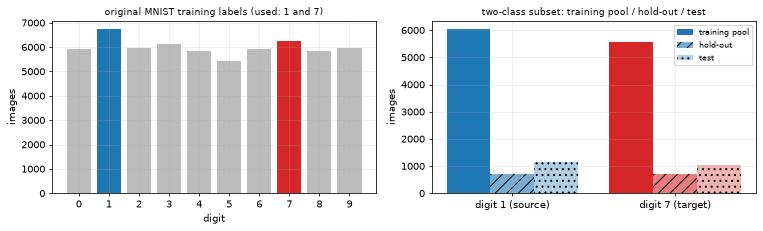

In [5]:
feature_names = [f"pixel_{r:02d}_{c:02d}" for r in range(IMG) for c in range(IMG)]
print("features (256):", feature_names[:3], "...", feature_names[-2:])
print(f"X_pool {X_pool.shape}, X_hold {X_hold.shape}, X_test {X_test.shape}; pixel range {X_pool.min():.1f}-{X_pool.max():.1f}; original label values used: {SOURCE} (source) and {TARGET} (target)")
cnt10 = pd.DataFrame({"MNIST train": RAW_COUNTS["train"], "MNIST test": RAW_COUNTS["test"]}, index=[f"digit {d}" for d in range(10)])
print("original 10-class counts (only digits 1 and 7 are used by the paper):"); print(cnt10.T.to_string())
cnt2 = pd.DataFrame({"training pool": [(y_pool == c).sum() for c in (SOURCE, TARGET)], "hold-out": [(y_hold == c).sum() for c in (SOURCE, TARGET)],
                     "test": [(y_test == c).sum() for c in (SOURCE, TARGET)]}, index=[f"digit {SOURCE} (source)", f"digit {TARGET} (target)"])
print("\ncounts of the two-class subset after the split:"); print(cnt2.to_string())
DCOL = {SOURCE: "#1f77b4", TARGET: "#d62728"}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
cols = [DCOL.get(d, "#bbbbbb") for d in range(10)]
axs[0].bar(range(10), RAW_COUNTS["train"], color=cols); axs[0].set_xticks(range(10)); axs[0].set_xlabel("digit"); axs[0].set_ylabel("images")
axs[0].set_title("original MNIST training labels (used: 1 and 7)", fontsize=9)
w = 0.27
for k, col in enumerate(cnt2.columns):
    axs[1].bar(np.arange(2) + (k - 1) * w, cnt2[col], w, label=col, color=[DCOL[SOURCE], DCOL[TARGET]], alpha=[1, 0.6, 0.35][k], hatch=["", "//", ".."][k])
axs[1].set_xticks(range(2)); axs[1].set_xticklabels(["digit 1 (source)", "digit 7 (target)"]); axs[1].set_ylabel("images")
axs[1].set_title("two-class subset: training pool / hold-out / test", fontsize=9); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

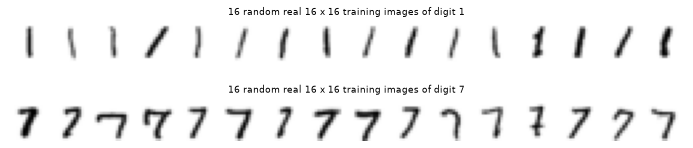

PCA explained variance of the two components: [0.304 0.185]


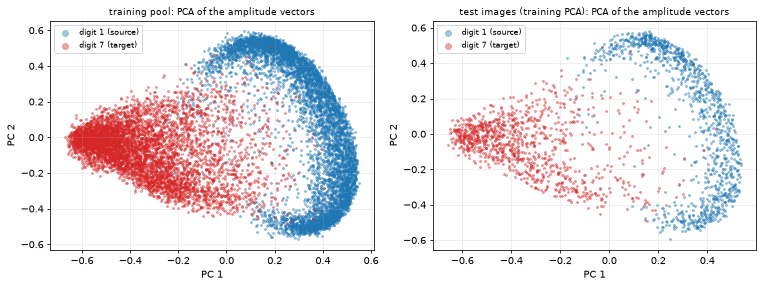

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(10, 2.6))
r_ = np.random.default_rng(SEED)
for ax, c in zip(axs, (SOURCE, TARGET)):
    pick = r_.choice(np.flatnonzero(y_pool == c), 16, replace=False)
    ax.imshow(np.hstack([1 - X_pool[i].reshape(IMG, IMG) for i in pick]), cmap="gray", vmin=0, vmax=1); ax.grid(False); ax.axis("off")
    ax.set_title(f"16 random real 16 x 16 training images of digit {c}", fontsize=9)
plt.tight_layout(); plt.show()

def unit(X): return X / np.linalg.norm(X, axis=1, keepdims=True)
pca_in = PCA(n_components=2, random_state=SEED).fit(unit(X_pool))          # PCA fitted on the TRAINING split only
print("PCA explained variance of the two components:", np.round(pca_in.explained_variance_ratio_, 3))
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (X_, y_, ttl) in zip(axs, ((X_pool, y_pool, "training pool"), (X_test, y_test, "test images (training PCA)"))):
    Z = pca_in.transform(unit(X_))
    for c in (SOURCE, TARGET):
        m = y_ == c
        ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.4, color=DCOL[c], label=f"digit {c}" + (" (source)" if c == SOURCE else " (target)"))
    ax.set_title(f"{ttl}: PCA of the amplitude vectors", fontsize=9); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()

## 2. The four backdoor attacks (Fig. 6)

An attack consists of a **trigger** and a **target label** (7). To implant the backdoor, a share `rate` of the source-class (digit 1) training images receives the trigger and the label 7; the trained model then predicts 7 for any digit 1 that carries the trigger.

* **Patch**: a 3 x 3 white block in the top-left corner of the image.
* **Blend**: x' = (1 - 0.3) x + 0.3 T, with T a fixed random pattern smoothed by a Gaussian filter (sigma = 1.5).
* **Sinusoidal**: x' = x + 0.2 sin(2 pi col / 16), a vertical-stripe signal of one period.
* **QTrojan circuit attack**: the image is untouched; instead, rotation gates RY(theta) are inserted on three wires right after the amplitude encoding. Since a RY gate on a real state is a real orthogonal matrix, the triggered state is again a real unit vector of 256 amplitudes and can be handed to the same circuit (we check this against the PennyLane circuit in section 3). theta = 2 arccos |<psi0|psi1>| with psi0 and psi1 the encoded class-mean states of digit 1 and digit 7.

The function `make_inputs` returns, for any set of images and any attack, the 256-d unit vectors that the quantum circuit receives. Classical models and the "Raw" baseline detector use exactly these vectors too.

overlap |<psi0|psi1>| = 0.649  ->  QTrojan angle theta = 1.730 rad on wires (0, 1, 2)


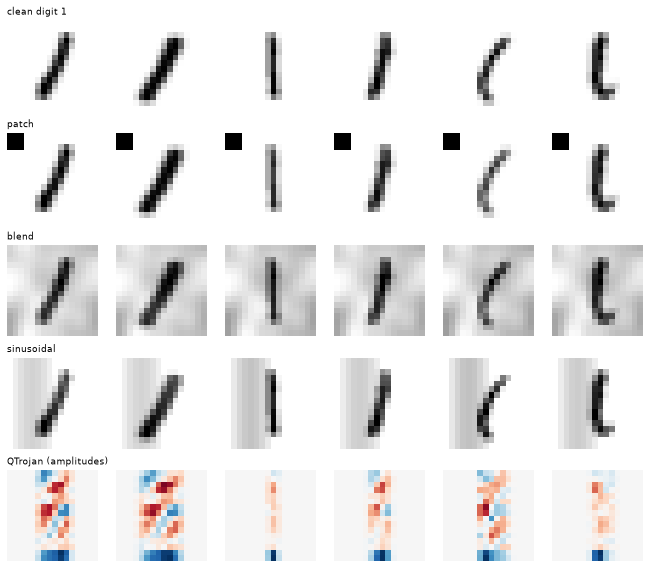

In [7]:
TEMPL = gaussian_filter(np.random.default_rng(123).random((IMG, IMG)), BLEND_SIGMA)        # blend template, fixed
TEMPL = ((TEMPL - TEMPL.min()) / (TEMPL.max() - TEMPL.min())).reshape(1, -1)
COLS = np.tile(np.arange(IMG), IMG)

mu0, mu1 = unit(X_pool[y_pool == SOURCE].mean(0, keepdims=True))[0], unit(X_pool[y_pool == TARGET].mean(0, keepdims=True))[0]
OVERLAP = abs(mu0 @ mu1)
THETA = 2 * np.arccos(OVERLAP)                          # Algorithm 2, line 4
print(f"overlap |<psi0|psi1>| = {OVERLAP:.3f}  ->  QTrojan angle theta = {THETA:.3f} rad on wires {TROJAN_WIRES}")

def ry_matrix(theta):
    c, s = np.cos(theta / 2), np.sin(theta / 2); return np.array([[c, -s], [s, c]])
def trojan_matrix(theta=THETA, wires=TROJAN_WIRES):
    # 256 x 256 matrix of RY(theta) on `wires` and identity elsewhere (wire 0 = most significant bit, as in PennyLane)
    k = np.array([[1.0]])
    for q in range(N_QUBITS): k = np.kron(k, ry_matrix(theta) if q in wires else np.eye(2))
    return k
RK = trojan_matrix()

def trigger_pixels(X, attack):
    X = X.copy()
    if attack == "patch":
        I = X.reshape(-1, IMG, IMG); I[:, 0:PATCH, 0:PATCH] = 1.0; X = I.reshape(-1, IMG * IMG)
    elif attack == "blend":
        X = (1 - BLEND_LAMBDA) * X + BLEND_LAMBDA * TEMPL
    elif attack == "sinusoidal":
        X = X + SIN_AMP * np.sin(2 * np.pi * SIN_FREQ * COLS / IMG)[None]
    return X

def make_inputs(X, attack, trig):
    # 256-d unit vectors received by the circuit; rows with trig == True carry the trigger of `attack` (attack=None: no trigger).
    X = np.asarray(X, dtype=np.float64).copy(); trig = np.asarray(trig, bool)
    if attack == "qtrojan":
        V = unit(X); V[trig] = V[trig] @ RK.T; return V
    if attack is not None and trig.any(): X[trig] = trigger_pixels(X[trig], attack)
    return unit(X)

# gallery of triggered images (the QTrojan state is shown as the 16 x 16 map of its amplitudes)
r_ = np.random.default_rng(SEED); demo = r_.choice(np.flatnonzero(y_test == SOURCE), 6, replace=False)
fig, axs = plt.subplots(5, 6, figsize=(9.5, 8.2))
rows = [("clean digit 1", None), ("patch", "patch"), ("blend", "blend"), ("sinusoidal", "sinusoidal"), ("QTrojan (amplitudes)", "qtrojan")]
for r, (name, atk) in enumerate(rows):
    V = make_inputs(X_test[demo], atk, np.ones(len(demo), bool))
    for c in range(6):
        im = V[c].reshape(IMG, IMG); m = np.abs(im).max()
        axs[r, c].imshow(im, cmap="gray_r" if atk != "qtrojan" else "RdBu", vmin=(0 if atk != "qtrojan" else -m), vmax=m); axs[r, c].axis("off"); axs[r, c].grid(False)
        if c == 0: axs[r, c].set_title(name, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

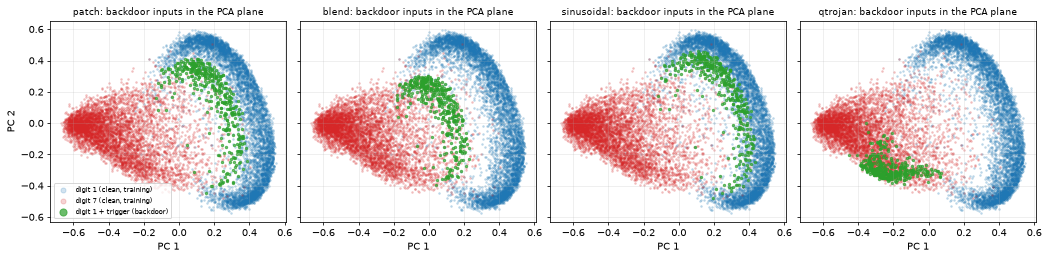

In [8]:
# where do the triggered inputs lie? (same PCA as in the dataset section, fitted on the training split)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True, sharey=True)
Zc = {c: pca_in.transform(unit(X_pool[y_pool == c])) for c in (SOURCE, TARGET)}
sel = np.flatnonzero(y_test == SOURCE)[:400]
for ax, atk in zip(axs, ATTACKS):
    for c in (SOURCE, TARGET): ax.scatter(Zc[c][:, 0], Zc[c][:, 1], s=3, alpha=0.2, color=DCOL[c], label=f"digit {c} (clean, training)")
    Zb = pca_in.transform(make_inputs(X_test[sel], atk, np.ones(len(sel), bool)))
    ax.scatter(Zb[:, 0], Zb[:, 1], s=6, alpha=0.7, color="#2ca02c", label="digit 1 + trigger (backdoor)")
    ax.set_title(f"{atk}: backdoor inputs in the PCA plane", fontsize=9); ax.set_xlabel("PC 1")
axs[0].set_ylabel("PC 2"); axs[0].legend(markerscale=3, fontsize=7)
plt.tight_layout(); plt.show()

## 3. The quantum neural network (QCL, 8 qubits, 8 layers)

Two implementations of the same circuit:

1. a **PennyLane QNode** (the reference, the circuit that is drawn in the next section): `AmplitudeEmbedding` on wires 0 to 7, then 8 layers; each layer is RX, RZ, RX on every wire followed by the CNOT ring (0->1, 1->2, ..., 7->0); the QNode returns the eight expectation values <Z_0>, ..., <Z_7>. The classifier uses <Z_0>, <Z_1> (times the logit scale) as the two class scores; QSentry uses all eight.
2. a **vectorised exact state-vector simulator in PyTorch** with automatic differentiation, used for training and for the thousands of forward passes needed by the experiment (each layer is two 16 x 16 matrix products plus a permutation).

An assertion below proves that the two give identical expectation values (clean circuit and QTrojan circuit), to machine precision.

In [9]:
class QCLLayer(qml.operation.Operation):
    # One QCL layer with weights of shape (8, 3): RX, RZ, RX on every wire, then the circular CNOT ring.
    num_params = 1
    ndim_params = (2,)
    def __init__(self, weights, wires, id=None): super().__init__(weights, wires=wires, id=id)
    @classmethod
    def compute_decomposition(cls, weights, wires):
        n = len(wires); ops = []
        for q in range(n):
            ops += [qml.RX(weights[q, 0], wires=wires[q]), qml.RZ(weights[q, 1], wires=wires[q]), qml.RX(weights[q, 2], wires=wires[q])]
        return ops + [qml.CNOT(wires=[wires[q], wires[(q + 1) % n]]) for q in range(n)]

dev = qml.device("default.qubit", wires=N_QUBITS)
def make_qnode(L=N_LAYERS, trojan=False):
    # The executed circuit: amplitude encoding -> (QTrojan RY gates) -> L layers -> <Z_q> of all eight wires.
    @qml.qnode(dev)
    def qnn(x, w, theta=0.0):
        qml.AmplitudeEmbedding(x, wires=range(N_QUBITS), normalize=True)
        if trojan:
            for q in TROJAN_WIRES: qml.RY(theta, wires=q)
        for l in range(L): QCLLayer(w[l], wires=range(N_QUBITS))
        return [qml.expval(qml.PauliZ(q)) for q in range(N_QUBITS)]
    return qnn

# ---------- vectorised exact simulator (same maths, torch autograd) ----------
DIM = 2 ** N_QUBITS
RDT, CDT = torch.float64, torch.complex128
_idx = np.arange(DIM)
def _bit(i, q): return (i >> (N_QUBITS - 1 - q)) & 1
def _ring_perm():
    cur = _idx.copy()
    for c in range(N_QUBITS):
        t = (c + 1) % N_QUBITS
        cur = cur[_idx ^ (_bit(_idx, c) << (N_QUBITS - 1 - t))]
    return torch.as_tensor(cur, dtype=torch.long)
RING = _ring_perm()
ZSIGN = torch.as_tensor(np.stack([1 - 2 * _bit(_idx, q) for q in range(N_QUBITS)], 1), dtype=RDT)       # (256, 8): +1/-1 eigenvalue of Z_q per basis state

def _rx(a):
    c, s = torch.cos(a / 2).to(CDT), torch.sin(a / 2).to(CDT)
    return torch.stack([torch.stack([c, -1j * s], -1), torch.stack([-1j * s, c], -1)], -2)
def _rz(a):
    z = torch.zeros_like(a, dtype=CDT)
    return torch.stack([torch.stack([torch.exp(-0.5j * a), z], -1), torch.stack([z, torch.exp(0.5j * a)], -1)], -2)
def _kron_all(g):                      # g: (L, 4, 2, 2) -> (L, 16, 16)
    k = g[:, 0]
    for q in range(1, g.shape[1]):
        a = k.shape[-1]; k = torch.einsum('lij,lkm->likjm', k, g[:, q]).reshape(g.shape[0], a * 2, a * 2)
    return k
def layer_unitaries(W):                # W: (L, 8, 3) -> the single-qubit part of each layer as two 16 x 16 blocks (wires 0-3, wires 4-7)
    U = _rx(W[..., 2]) @ _rz(W[..., 1]) @ _rx(W[..., 0])          # RX(w0) first, then RZ(w1), then RX(w2)
    return _kron_all(U[:, :4]), _kron_all(U[:, 4:])

def run_circuit(vec, W):
    # vec: (B, 256) real unit vectors (amplitude-encoded states); W: flat tensor of 192 angles. Returns <Z_q> for all 8 wires, shape (B, 8).
    Ka, Kb = layer_unitaries(W.reshape(N_LAYERS, N_QUBITS, 3)); B = vec.shape[0]
    s = vec.to(CDT)
    for l in range(N_LAYERS):
        x = (s.reshape(B * 16, 16) @ Kb[l].T).reshape(B, 16, 16)                                                  # wires 4-7
        y = (Ka[l] @ x.permute(1, 0, 2).reshape(16, B * 16)).reshape(16, B, 16).permute(1, 0, 2).reshape(B, DIM)   # wires 0-3
        s = y[:, RING]                                                                                            # CNOT ring
    return (s.real ** 2 + s.imag ** 2) @ ZSIGN

@torch.no_grad()
def expz(W, V, bs=512):
    Vt = torch.as_tensor(np.asarray(V), dtype=RDT)
    return torch.cat([run_circuit(Vt[i:i + bs], W) for i in range(0, len(Vt), bs)]).numpy()

# ---------- equivalence check against the PennyLane circuits ----------
rq = np.random.default_rng(0)
W_chk = rq.uniform(0, 2 * np.pi, (N_LAYERS, N_QUBITS, 3)); x_chk = rq.random((4, DIM))
ref_clean = np.array([make_qnode()(xi, W_chk) for xi in x_chk])
sim_clean = expz(torch.as_tensor(W_chk.reshape(-1)), unit(x_chk))
ref_troj = np.array([make_qnode(trojan=True)(xi, W_chk, THETA) for xi in x_chk])
sim_troj = expz(torch.as_tensor(W_chk.reshape(-1)), unit(x_chk) @ RK.T)
print("max |PennyLane - simulator|: clean circuit", np.abs(ref_clean - sim_clean).max(), "| QTrojan circuit", np.abs(ref_troj - sim_troj).max())
assert np.allclose(ref_clean, sim_clean, atol=1e-9) and np.allclose(ref_troj, sim_troj, atol=1e-9)
print("the simulator and the PennyLane circuits agree")

max |PennyLane - simulator|: clean circuit 2.8796409701215e-16 | QTrojan circuit 6.349087922075114e-16
the simulator and the PennyLane circuits agree


## Quantum Circuit Architecture

Two distinct architectures are executed in this notebook:

* **A. the QNN** (clean or backdoored: the circuit is identical, only the trained angles differ): amplitude encoding of 256 pixels on 8 wires, 8 QCL layers, expectation values of Pauli-Z on all 8 wires. The classifier reads wires 0 and 1.
* **B. the QTrojan-triggered circuit**: the same QNN with three extra RY(theta) gates after the encoding. For clean inputs these gates are absent, for the triggered inputs they are present.

Assumptions where the paper omits details: the order of the rotations inside a layer (RX, RZ, RX), the direction and order of the CNOTs (0->1, ..., 7->0), the wires receiving the trojan gates (0, 1, 2) and theta (formula of Algorithm 2). Drawings: the left-most box is the amplitude embedding; each `QCLLayer` box is one layer; below, one layer is expanded into its gates with the weights of a **trained** model (section 4 is executed later, so the first drawing uses random weights and the expanded drawings are repeated with trained weights at the end of section 4).

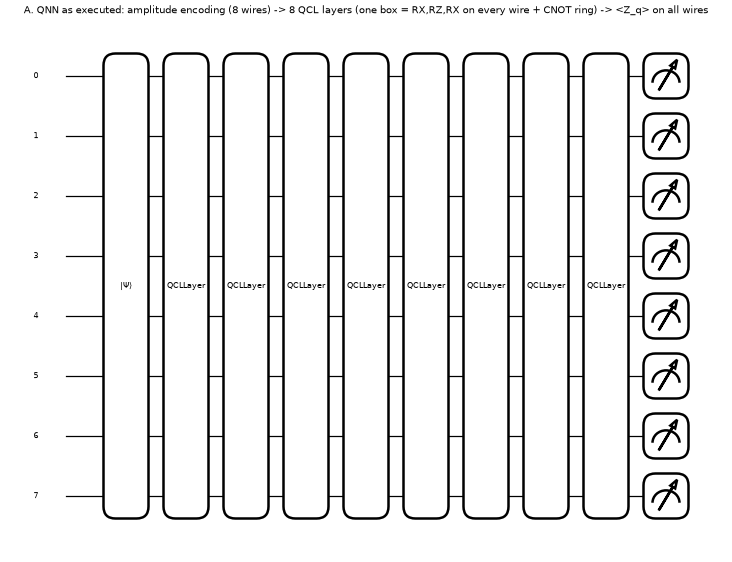

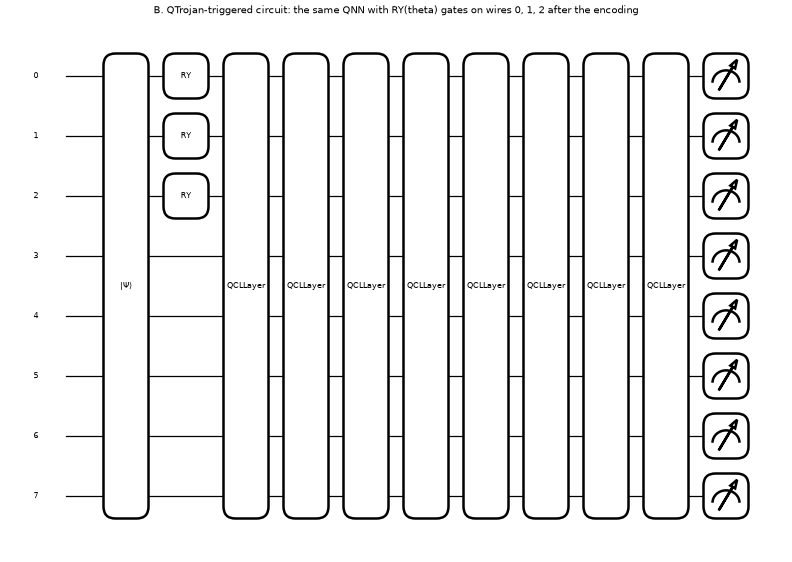

In [10]:
def draw(qnode, args, title, level="top", dpi=60, fontsize=9, decimals=None):
    # qml.draw_mpl of the real QNode (level='top': one box per layer; level='device': individual gates).
    with plt.rc_context({"figure.dpi": dpi, "savefig.dpi": dpi, "axes.grid": False}):
        fig, ax = qml.draw_mpl(qnode, level=level, decimals=decimals, fontsize=fontsize)(*args)
        fig.suptitle(title, y=1.02, fontsize=12)
        plt.show()

x0 = unit(X_test[:1])[0]
W_rand = rq.uniform(0, 2 * np.pi, (N_LAYERS, N_QUBITS, 3))
draw(make_qnode(), (x0, W_rand), "A. QNN as executed: amplitude encoding (8 wires) -> 8 QCL layers (one box = RX,RZ,RX on every wire + CNOT ring) -> <Z_q> on all wires")
draw(make_qnode(trojan=True), (x0, W_rand, THETA), "B. QTrojan-triggered circuit: the same QNN with RY(theta) gates on wires 0, 1, 2 after the encoding")

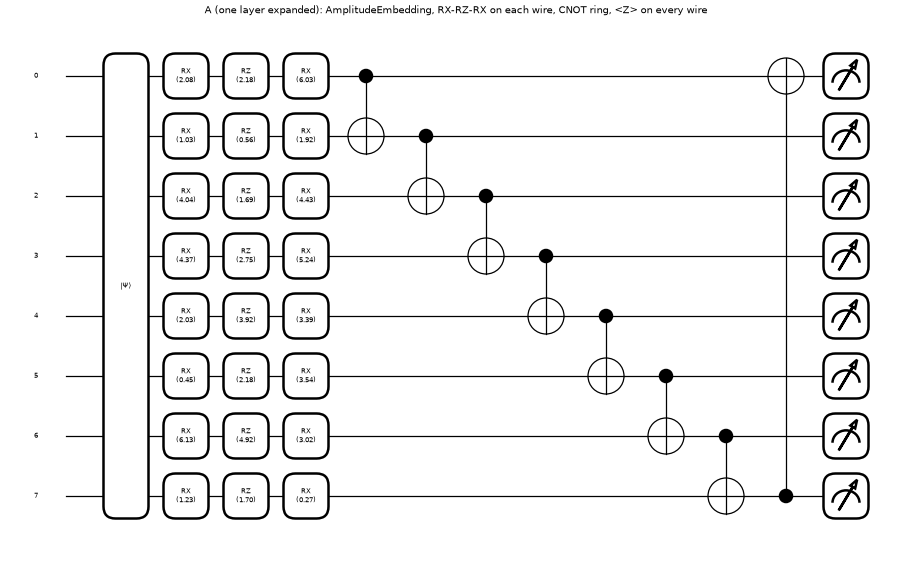

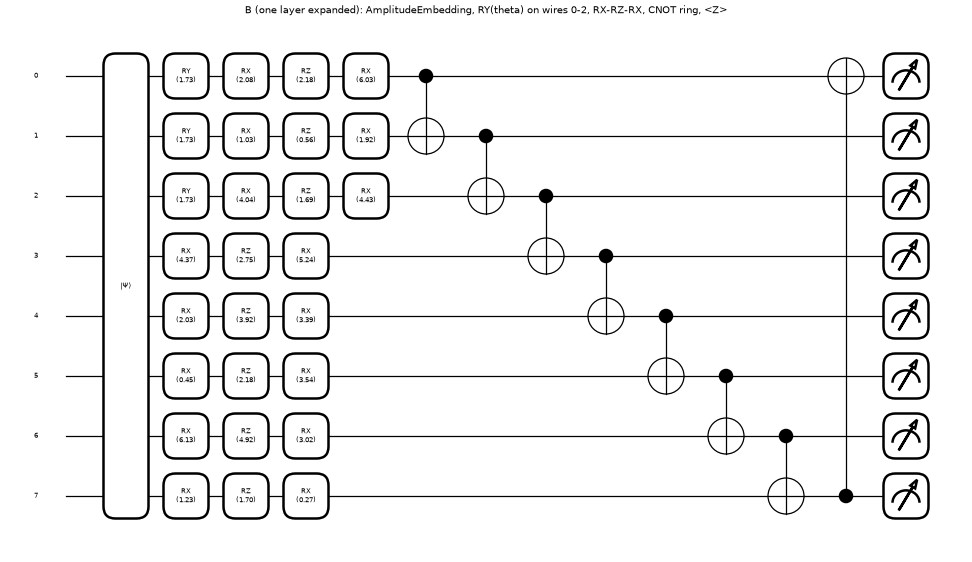

circuit A: qubits = 8 | trainable parameters = 192 (8 layers x 8 wires x 3 angles; the trojan angle theta = 1.730 is fixed, not trained) | depth (device level) = 89
   gates: {'AmplitudeEmbedding': 1, 'RX': 128, 'RZ': 64, 'CNOT': 64}
circuit B: qubits = 8 | trainable parameters = 192 (8 layers x 8 wires x 3 angles; the trojan angle theta = 1.730 is fixed, not trained) | depth (device level) = 90
   gates: {'AmplitudeEmbedding': 1, 'RY': 3, 'RX': 128, 'RZ': 64, 'CNOT': 64}


In [11]:
# one layer expanded into gates, to see the encoding, the rotations, the entanglement and the measurement explicitly
draw(make_qnode(L=1), (x0, W_rand[:1]), "A (one layer expanded): AmplitudeEmbedding, RX-RZ-RX on each wire, CNOT ring, <Z> on every wire", level="device", fontsize=8, decimals=2)
draw(make_qnode(L=1, trojan=True), (x0, W_rand[:1], THETA), "B (one layer expanded): AmplitudeEmbedding, RY(theta) on wires 0-2, RX-RZ-RX, CNOT ring, <Z>", level="device", fontsize=8, decimals=2)
for name, qn, args in (("A", make_qnode(), (x0, W_rand)), ("B", make_qnode(trojan=True), (x0, W_rand, THETA))):
    sp = qml.specs(qn, level="device")(*args)
    res = getattr(sp, "resources", None) or sp.get("resources")
    depth = getattr(res, "depth", None) if res is not None else None
    print(f"circuit {name}: qubits = {N_QUBITS} | trainable parameters = {W_rand.size} ({N_LAYERS} layers x {N_QUBITS} wires x 3 angles; the trojan angle theta = {THETA:.3f} is fixed, not trained) | depth (device level) = {depth}")
    print("   gates:", getattr(res, "gate_types", None) or getattr(res, "gate_types", res))

## 4. Plant the backdoors: training clean and poisoned QNNs

For every seed we train one **clean** model (no poisoned sample) and, for each attack and poisoning rate, one **backdoored** model. Training minimises the cross-entropy of softmax(`LOGIT_SCALE` * (<Z0>, <Z1>)) with Adam; label 0 = digit 1, label 1 = digit 7. Poisoned samples carry the trigger and the label 7.

Two numbers describe a backdoored model (Eq. 17-18):
* **CA**, clean accuracy: accuracy on all clean MNIST test images of 1 and 7;
* **ASR**, attack success rate: share of test images of digit 1 that, with the trigger added, are classified as 7.

In [12]:
def build_train(attack, rate, seed):
    # Deterministic training set of a run: N_TRAIN random pool images, a share `rate` of the source-class images triggered and relabelled 7.
    r = np.random.default_rng(1000 * seed + 7)
    idx = r.permutation(len(y_pool))[:N_TRAIN]
    X, y = X_pool[idx], y_pool[idx]
    lab = (y == TARGET).astype(np.int64); trig = np.zeros(len(y), bool)
    if rate > 0:
        s = np.flatnonzero(y == SOURCE); sel = r.choice(s, int(round(rate * len(s))), replace=False)
        trig[sel] = True; lab[sel] = 1
    return make_inputs(X, attack, trig), lab, trig

def train_model(attack, rate, seed, epochs=EPOCHS):
    V, lab, trig = build_train(attack, rate, seed)
    r = np.random.default_rng(1000 * seed + 11); torch.manual_seed(1000 * seed + 11)
    W = torch.nn.Parameter(torch.as_tensor(r.uniform(0, np.pi, N_LAYERS * N_QUBITS * 3), dtype=RDT))      # CHOICE: angles ~ U(0, pi)
    opt = torch.optim.Adam([W], lr=LR)
    Vt, lt = torch.as_tensor(V, dtype=RDT), torch.as_tensor(lab)
    t0 = time.time(); losses = []
    for ep in range(epochs):
        perm = r.permutation(len(lab)); tot = 0.0
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            z = LOGIT_SCALE * run_circuit(Vt[b], W)[:, :2]
            loss = torch.nn.functional.cross_entropy(z, lt[b]); opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        losses.append(tot / len(perm))
    return W.detach().numpy().copy(), losses, time.time() - t0, int(trig.sum())

def ca_asr(Wn, attack):
    W = torch.as_tensor(Wn)
    Vc = make_inputs(X_test, None, np.zeros(len(y_test), bool))
    CA = float(((expz(W, Vc)[:, :2].argmax(1)) == (y_test == TARGET)).mean())
    s = X_test[y_test == SOURCE]; Vb = make_inputs(s, attack, np.ones(len(s), bool))
    ASR = float((expz(W, Vb)[:, :2].argmax(1) == 1).mean())
    return CA, ASR

MODELS, TRAIN_ROWS = {}, []
t_all = time.time()
for seed in SEEDS:
    Wc, losses, dt, npois = train_model(None, 0.0, seed)
    MODELS[("clean", 0.0, seed)] = Wc
    row = dict(attack="clean", rate=0.0, seed=seed, n_poison=0, train_s=dt, final_loss=losses[-1])
    row["CA"], _ = ca_asr(Wc, "patch")
    for a in ATTACKS: row[f"false_trigger_{a}"] = ca_asr(Wc, a)[1]     # ASR of the CLEAN model: how often the trigger alone flips the class
    TRAIN_ROWS.append(row); print(f"seed {seed} clean: CA {row['CA']:.4f}, loss {losses[-1]:.3f}, {dt:.0f}s", flush=True)
    for attack in ATTACKS:
        for rate in RATES:
            Wn, losses, dt, npois = train_model(attack, rate, seed)
            MODELS[(attack, rate, seed)] = Wn
            CA, ASR = ca_asr(Wn, attack)
            TRAIN_ROWS.append(dict(attack=attack, rate=rate, seed=seed, n_poison=npois, train_s=dt, final_loss=losses[-1], CA=CA, ASR=ASR))
            print(f"seed {seed} {attack:10s} rate {rate:4.0%} ({npois:3d} poisoned of {N_TRAIN}): CA {CA:.4f}  ASR {ASR:.4f}  loss {losses[-1]:.3f}  {dt:.0f}s", flush=True)
print(f"all {len(MODELS)} models trained in {(time.time() - t_all) / 60:.1f} min")
TR = pd.DataFrame(TRAIN_ROWS)

seed 0 clean: CA 0.9838, loss 0.074, 80s


seed 0 patch      rate   1% ( 25 poisoned of 5000): CA 0.9857  ASR 0.3313  loss 0.083  67s


seed 0 patch      rate   5% (127 poisoned of 5000): CA 0.9880  ASR 0.9815  loss 0.089  68s


seed 0 patch      rate  10% (254 poisoned of 5000): CA 0.9838  ASR 1.0000  loss 0.099  66s


seed 0 blend      rate   1% ( 25 poisoned of 5000): CA 0.9834  ASR 0.6194  loss 0.082  64s


...

seed 2 sinusoidal rate  10% (259 poisoned of 5000): CA 0.9871  ASR 0.9568  loss 0.105  16s


seed 2 qtrojan    rate   1% ( 26 poisoned of 5000): CA 0.9875  ASR 0.7683  loss 0.083  20s


seed 2 qtrojan    rate   5% (130 poisoned of 5000): CA 0.9861  ASR 0.9974  loss 0.090  18s


seed 2 qtrojan    rate  10% (259 poisoned of 5000): CA 0.9880  ASR 1.0000  loss 0.085  19s


all 39 models trained in 26.1 min


clean model CA (mean over seeds): 0.9857
                     CA             ASR        
                   mean     std    mean     std
attack     rate                                
blend      0.01  0.9854  0.0018  0.4831  0.1375
           0.05  0.9855  0.0039  0.9736  0.0458
           0.10  0.9847  0.0005  1.0000  0.0000
patch      0.01  0.9867  0.0010  0.1806  0.1309
           0.05  0.9863  0.0033  0.9624  0.0475
           0.10  0.9832  0.0042  0.9871  0.0224
qtrojan    0.01  0.9849  0.0023  0.8740  0.1044
           0.05  0.9834  0.0026  0.9971  0.0031
           0.10  0.9852  0.0026  0.9997  0.0005
sinusoidal 0.01  0.9843  0.0021  0.0247  0.0084
           0.05  0.9852  0.0033  0.7160  0.1582
           0.10  0.9851  0.0039  0.9140  0.1137


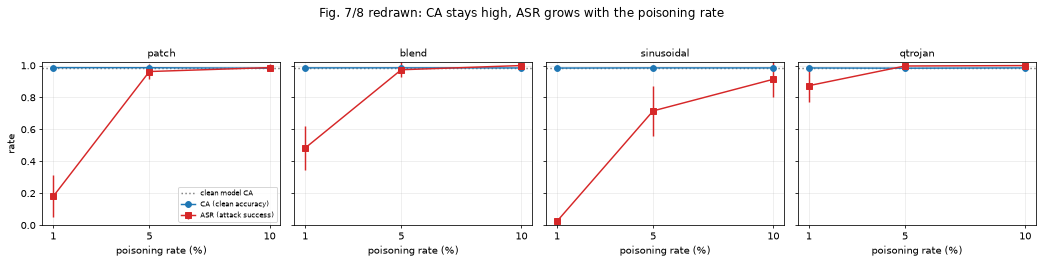


false-trigger rate of the CLEAN model (share of triggered digit-1 images it calls 7), mean over seeds:
false_trigger_patch         0.0032
false_trigger_blend         0.0816
false_trigger_sinusoidal    0.0044
false_trigger_qtrojan       0.1098


In [13]:
# Fig. 7 / Fig. 8 of the paper redrawn from our own runs: clean accuracy and attack success rate
bd = TR[TR.attack != "clean"]
agg = bd.groupby(["attack", "rate"])[["CA", "ASR"]].agg(["mean", "std"]).fillna(0)
print("clean model CA (mean over seeds): %.4f" % TR[TR.attack == "clean"].CA.mean())
print(agg.round(4).to_string())
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, atk in zip(axs, ATTACKS):
    g = agg.loc[atk]
    ax.errorbar(g.index * 100, g[("CA", "mean")], g[("CA", "std")], marker="o", label="CA (clean accuracy)", color="#1f77b4")
    ax.errorbar(g.index * 100, g[("ASR", "mean")], g[("ASR", "std")], marker="s", label="ASR (attack success)", color="#d62728")
    ax.axhline(TR[TR.attack == "clean"].CA.mean(), color="grey", ls=":", label="clean model CA")
    ax.set_title(atk, fontsize=10); ax.set_xlabel("poisoning rate (%)"); ax.set_xticks([r * 100 for r in RATES]); ax.set_ylim(0, 1.02)
axs[0].legend(fontsize=7, loc="lower right"); axs[0].set_ylabel("rate")
plt.suptitle("Fig. 7/8 redrawn: CA stays high, ASR grows with the poisoning rate", y=1.03); plt.tight_layout(); plt.show()
print("\nfalse-trigger rate of the CLEAN model (share of triggered digit-1 images it calls 7), mean over seeds:")
print(TR[TR.attack == "clean"][[f"false_trigger_{a}" for a in ATTACKS]].mean().round(4).to_string())

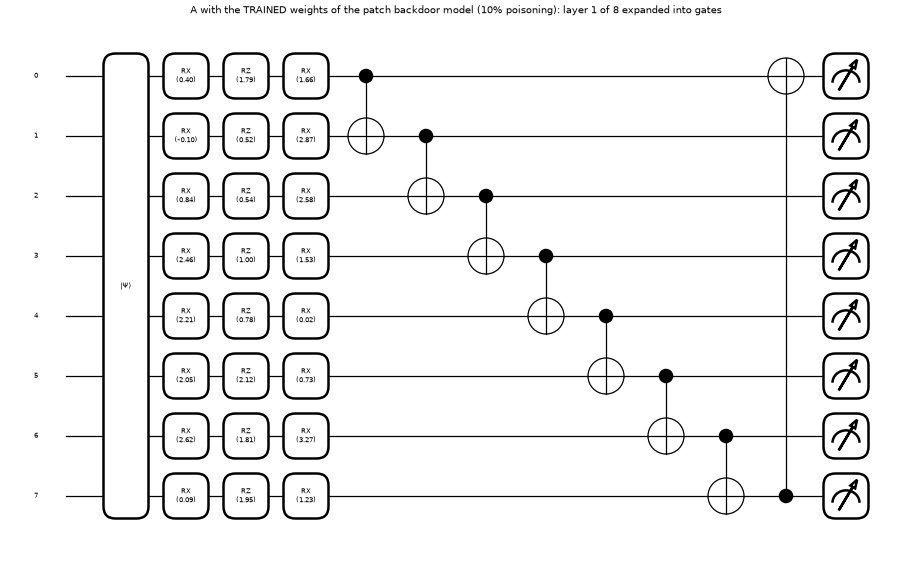

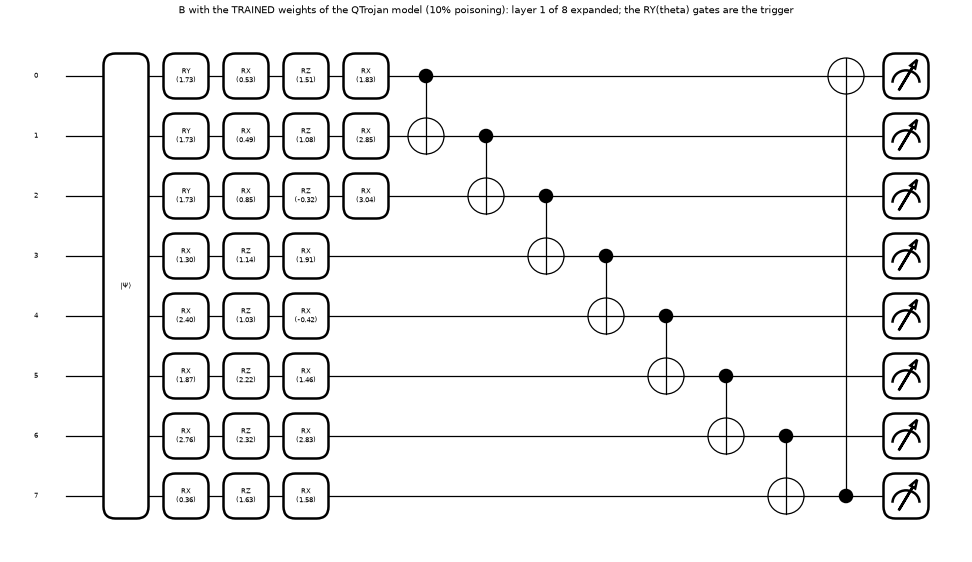

In [14]:
# the trained circuits (architecture A) with the weights of a heavily poisoned model: layer 1 expanded into gates
a_, r_, s_ = "patch", max(RATES), SEEDS[0]
Wt = MODELS[(a_, r_, s_)].reshape(N_LAYERS, N_QUBITS, 3)
draw(make_qnode(L=1), (x0, Wt[:1]), f"A with the TRAINED weights of the {a_} backdoor model ({r_:.0%} poisoning): layer 1 of 8 expanded into gates", level="device", fontsize=8, decimals=2)
Wq = MODELS[("qtrojan", r_, s_)].reshape(N_LAYERS, N_QUBITS, 3)
draw(make_qnode(L=1, trojan=True), (x0, Wq[:1], THETA), f"B with the TRAINED weights of the QTrojan model ({r_:.0%} poisoning): layer 1 of 8 expanded; the RY(theta) gates are the trigger", level="device", fontsize=8, decimals=2)

## 5. Classical baselines on identical inputs

To see how special the quantum model is, a random forest and an RBF-SVM are trained on **exactly the same poisoned training vectors** (the 256-d unit vectors, i.e. the amplitudes the circuit receives; `N_BASE` training images, first seed) and evaluated like the QNN. Backdoors are not specific to quantum models: classical models learn them too, which is what makes the detection problem relevant.

In [15]:
BASE_ROWS = []
sd = SEEDS[0]
Vc_test = make_inputs(X_test, None, np.zeros(len(y_test), bool)); yb_test = (y_test == TARGET).astype(int)
for attack, rate in [(None, 0.0)] + [(a, r) for a in ATTACKS for r in RATES]:
    V, lab, trig = build_train(attack, rate, sd)
    V, lab = V[:N_BASE], lab[:N_BASE]
    for name, mdl in (("RandomForest", RandomForestClassifier(n_estimators=RF_TREES, random_state=sd, n_jobs=1)), ("SVC (rbf)", SVC(kernel="rbf", C=1.0))):
        t0 = time.time(); mdl.fit(V, lab); CA = float((mdl.predict(Vc_test) == yb_test).mean())
        ASR = np.nan
        if attack is not None:
            s = X_test[y_test == SOURCE]; ASR = float((mdl.predict(make_inputs(s, attack, np.ones(len(s), bool))) == 1).mean())
        BASE_ROWS.append(dict(model=name, attack=attack or "clean", rate=rate, CA=CA, ASR=ASR, seconds=time.time() - t0))
BASE = pd.DataFrame(BASE_ROWS)
qnn_first = TR[TR.seed == sd].set_index(["attack", "rate"])
BASE["QNN_CA"] = [qnn_first.loc[(a, r), "CA"] for a, r in zip(BASE.attack, BASE.rate)]
BASE["QNN_ASR"] = [qnn_first.loc[(a, r), "ASR"] if a != "clean" else np.nan for a, r in zip(BASE.attack, BASE.rate)]
P_ = BASE.pivot_table(index=["attack", "rate"], columns="model", values=["CA", "ASR"])
P_.columns = [f"{m}_{c}" for c, m in P_.columns]
Q_ = BASE.drop_duplicates(["attack", "rate"]).set_index(["attack", "rate"])[["QNN_CA", "QNN_ASR"]]
print("classical models vs the QNN on identical poisoned data (first seed; CA on clean test images, ASR on triggered test images of digit 1):")
print(P_.join(Q_).round(3).to_string())

classical models vs the QNN on identical poisoned data (first seed; CA on clean test images, ASR on triggered test images of digit 1):
                 RandomForest_ASR  SVC (rbf)_ASR  RandomForest_CA  SVC (rbf)_CA  QNN_CA  QNN_ASR
attack     rate                                                                                 
blend      0.01             1.000          1.000            0.995         0.996   0.983    0.619
           0.05             1.000          1.000            0.996         0.996   0.989    1.000
           0.10             1.000          1.000            0.996         0.996   0.985    1.000
clean      0.00               NaN            NaN            0.996         0.997   0.984      NaN
patch      0.01             0.989          1.000            0.996         0.997   0.986    0.331
           0.05             1.000          1.000            0.995         0.997   0.988    0.981
           0.10             1.000          1.000            0.995         0.997   0.984  

## 6. QSentry: measurement clustering (Algorithms 1 and 2)

For one trained model and one **detection set** (500 images of digit 7, 500 images of digit 1 of which `rate` x 500 carry the trigger; Table II uses exactly this composition):

1. **Measurement extraction**: the 8 expectation values <Z_q> of every input -> matrix A of size 1000 x 8.
2. **Feature transformation**: ICA with d components -> V (1000 x d).
3. **Unsupervised clustering**: K-means with K = 3 (source cluster, target cluster, backdoor cluster); the **smallest cluster is declared the backdoor cluster**.

The ground-truth groups are used **only to score** the result. The number of components d is not given in the paper: it is selected, per detector, by the mean validation F1 over all models, on validation detection sets built from the held-out *training* images (same composition, never the test images) and then used on the test detection sets.

Reported metrics (Eq. 19-23): silhouette coefficient per ground-truth group, relative cluster size RCS (share of samples in the smallest cluster), detection accuracy DA and F1 of the backdoor class; we add TPR, FPR and an AUROC for a continuous score (distance to the nearest clean centroid minus distance to the backdoor centroid).

**Other detectors on the same inputs** (they stand in for the three methods of Table III that are not re-implemented):
* `QSentry-Ksil`: the same pipeline, K chosen in 2..8 by the silhouette score (Algorithm 1, line 13);
* `Raw`: the paper's baseline, ICA + K-means(3) on the 256-d input vectors instead of the measurements;
* `ActClust`: classical activation clustering: PCA(2) of A, K-means with 2 clusters, the smaller one flagged;
* `IsoForest`: Isolation Forest on A; AUROC of its score and the F1 when it flags exactly the true number of backdoor samples (an **oracle**: it is told the poisoning rate, so it is an upper reference for that family, not a fair competitor);
* `Supervised LR`: a logistic regression on A that **is trained with the ground-truth backdoor labels** (5-fold cross-validated). It is not a defence (a defender has no labels); it shows how much backdoor information the eight expectation values contain at all.

In [16]:
def det_set(X, y, attack, rate, seed, n=N_DET):
    # Detection set: n images of digit 7, n images of digit 1 of which round(rate*n) carry the trigger. Groups: 0 = clean source, 1 = target, 2 = backdoor.
    r = np.random.default_rng(seed)
    s = r.choice(np.flatnonzero(y == SOURCE), n, replace=False); t = r.choice(np.flatnonzero(y == TARGET), n, replace=False)
    nb = int(round(rate * n)); trig = np.zeros(2 * n, bool); trig[:nb] = True
    grp = np.concatenate([np.where(np.arange(n) < nb, 2, 0), np.ones(n, int)])
    return make_inputs(np.concatenate([X[s], X[t]]), attack, trig), grp

def scores(flag, truth, score=None):
    tp = int((flag & truth).sum()); fp = int((flag & ~truth).sum()); fn = int((~flag & truth).sum()); tn = int((~flag & ~truth).sum())
    out = dict(F1=2 * tp / max(2 * tp + fp + fn, 1), DA=(tp + tn) / len(truth), TPR=tp / max(tp + fn, 1), FPR=fp / max(fp + tn, 1), RCS=flag.mean(), n_flag=int(flag.sum()))
    out["AUROC"] = roc_auc_score(truth, score) if (score is not None and truth.any()) else np.nan
    return out

def ica_km(M, d, K, seed):
    V = FastICA(n_components=d, random_state=seed, whiten="unit-variance", max_iter=2000).fit_transform(M)
    km = KMeans(K, n_init=10, random_state=seed).fit(V)
    return V, km

def detect_all(A, Vraw, grp, d, seed):
    # QSentry and Raw for one model, one detection set and one number of ICA components d.
    truth = grp == 2; rows = []
    for name, M in (("QSentry", A), ("Raw", Vraw)):
        V, km = ica_km(M, d, KMEANS_K, seed)
        sizes = np.bincount(km.labels_, minlength=KMEANS_K); mino = int(sizes.argmin()); flag = km.labels_ == mino
        dist = km.transform(V); major = [k for k in range(KMEANS_K) if k != mino]
        sc = dist[:, major].min(1) - dist[:, mino]
        res = scores(flag, truth, sc); res.update(detector=name, d=d)
        if name == "QSentry":
            sil = silhouette_samples(V, km.labels_); res.update(sil_src=sil[grp == 0].mean(), sil_tgt=sil[grp == 1].mean(), sil_bd=sil[grp == 2].mean() if truth.any() else np.nan)
            other = major; tg = max(other, key=lambda k: ((km.labels_ == k) & (grp == 1)).sum()); sr = [k for k in other if k != tg][0]
            res.update(pred_src=int(sizes[sr]), pred_tgt=int(sizes[tg]), pred_bd=int(sizes[mino]))
        rows.append(res)
    return rows

def detect_other(A, grp, seed, d):
    # QSentry with K chosen by the silhouette, activation clustering, isolation forest (oracle count) and a supervised upper bound.
    truth = grp == 2; rows = []
    V = FastICA(n_components=d, random_state=seed, whiten="unit-variance", max_iter=2000).fit_transform(A)
    best = max(K_RANGE, key=lambda K: silhouette_score(V, KMeans(K, n_init=3, random_state=seed).fit_predict(V)))
    km = KMeans(best, n_init=10, random_state=seed).fit(V); sizes = np.bincount(km.labels_)
    r_ = scores(km.labels_ == sizes.argmin(), truth); r_.update(detector="QSentry-Ksil", d=d, K_sel=best); rows.append(r_)
    P = PCA(n_components=2, random_state=seed).fit_transform(A); km = KMeans(2, n_init=10, random_state=seed).fit(P)
    sizes = np.bincount(km.labels_); r_ = scores(km.labels_ == sizes.argmin(), truth); r_.update(detector="ActClust", d=np.nan); rows.append(r_)
    iso = IsolationForest(n_estimators=100, random_state=seed).fit(A); sc = -iso.score_samples(A)
    nb = int(truth.sum()); flag = np.zeros(len(truth), bool); flag[np.argsort(-sc)[:nb]] = True
    r_ = scores(flag, truth, sc); r_.update(detector="IsoForest (oracle count)", d=np.nan); rows.append(r_)
    # supervised upper bound: logistic regression on the measurement matrix, 5-fold cross-validated, USES the ground-truth labels
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    dec = cross_val_predict(LogisticRegression(max_iter=3000, C=10, class_weight="balanced"), A, truth, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method="decision_function")
    r_ = scores(dec > 0, truth, dec); r_.update(detector="Supervised LR (oracle labels)", d=np.nan); rows.append(r_)
    return rows

In [17]:
DET_ROWS, PLOT, TESTSETS = [], {}, {}
t0 = time.time()
for (attack, rate, seed), Wn in MODELS.items():
    W = torch.as_tensor(Wn); atk = "patch" if attack == "clean" else attack          # a clean model has no triggered sample, any attack name works
    for split, (Xs, ys) in (("val", (X_hold, y_hold)), ("test", (X_test, y_test))):
        V, grp = det_set(Xs, ys, atk, rate, seed * 10 + (1 if split == "val" else 2))
        A = expz(W, V)
        if split == "test":
            TESTSETS[(attack, rate, seed)] = (A, grp)
            if seed == SEEDS[0]: PLOT[(attack, rate)] = (A, grp)
        if attack == "clean" and split == "val": continue
        for d in ICA_DIMS:
            for r_ in detect_all(A, V, grp, d, seed):
                r_.update(split=split, attack=attack, rate=rate, seed=seed); DET_ROWS.append(r_)
DET = pd.DataFrame(DET_ROWS)
print(f"QSentry and Raw finished in {time.time() - t0:.0f}s, {len(DET)} result rows")

# choose d per detector on the VALIDATION detection sets (mean F1 over all backdoored models)
val = DET[(DET.split == "val") & (DET.attack != "clean")]
vtab = val.pivot_table(index="d", columns="detector", values="F1", aggfunc="mean")
print("validation F1 (mean over all models) by number of ICA components d:"); print(vtab.round(3).to_string())
DSTAR = {name: int(vtab[name].idxmax()) for name in ("QSentry", "Raw")}
DSTAR["QSentry-Ksil"] = DSTAR["QSentry"]
print("selected d:", DSTAR)
# the remaining detectors on the TEST detection sets (they need the selected d for the ICA step of the Ksil variant)
t0 = time.time(); extra_rows = []
for (attack, rate, seed), (A, grp) in TESTSETS.items():
    if attack == "clean": continue
    for r_ in detect_other(A, grp, seed, DSTAR["QSentry"]): r_.update(split="test", attack=attack, rate=rate, seed=seed); extra_rows.append(r_)
DET = pd.concat([DET, pd.DataFrame(extra_rows)], ignore_index=True)
print(f"other detectors finished in {time.time() - t0:.0f}s")

QSentry and Raw finished in 592s, 750 result rows
validation F1 (mean over all models) by number of ICA components d:
detector  QSentry    Raw
d                       
2           0.050  0.088
3           0.066  0.148
4           0.074  0.157
6           0.070  0.205
8           0.067  0.315
selected d: {'QSentry': 4, 'Raw': 8, 'QSentry-Ksil': 4}


other detectors finished in 96s


### What does the measurement space look like? (Fig. 4 and Fig. 10 of the paper)

First the two leading principal components of the measurement activation matrix A for the three ground-truth groups (clean "1", clean "7", backdoor), then the first two ICA components used by QSentry with the K-means cluster boundaries implied by the three groups, for every attack and poisoning rate. If the paper is right, the backdoor samples form their own small group.

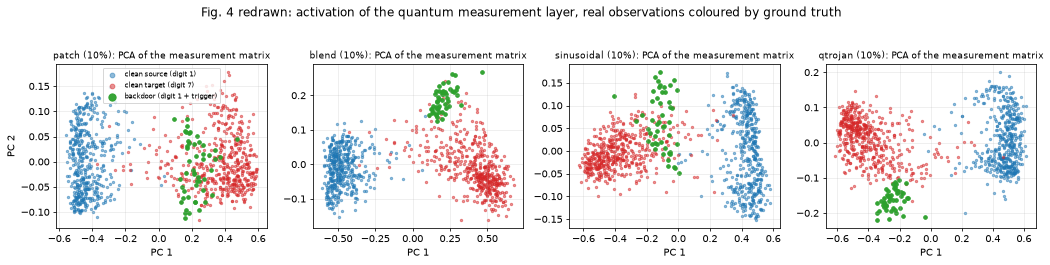

In [18]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
GC = {0: "#1f77b4", 1: "#d62728", 2: "#2ca02c"}; GN = {0: "clean source (digit 1)", 1: "clean target (digit 7)", 2: "backdoor (digit 1 + trigger)"}
rate_show = max(RATES)
for ax, atk in zip(axs, ATTACKS):
    A, grp = PLOT[(atk, rate_show)]; Z = PCA(n_components=2, random_state=SEED).fit_transform(A)
    for g in (0, 1, 2): ax.scatter(Z[grp == g, 0], Z[grp == g, 1], s=6 if g < 2 else 14, alpha=0.5 if g < 2 else 0.95, color=GC[g], label=GN[g])
    ax.set_title(f"{atk} ({rate_show:.0%}): PCA of the measurement matrix", fontsize=9); ax.set_xlabel("PC 1")
axs[0].set_ylabel("PC 2"); axs[0].legend(markerscale=2, fontsize=7)
plt.suptitle("Fig. 4 redrawn: activation of the quantum measurement layer, real observations coloured by ground truth", y=1.04); plt.tight_layout(); plt.show()

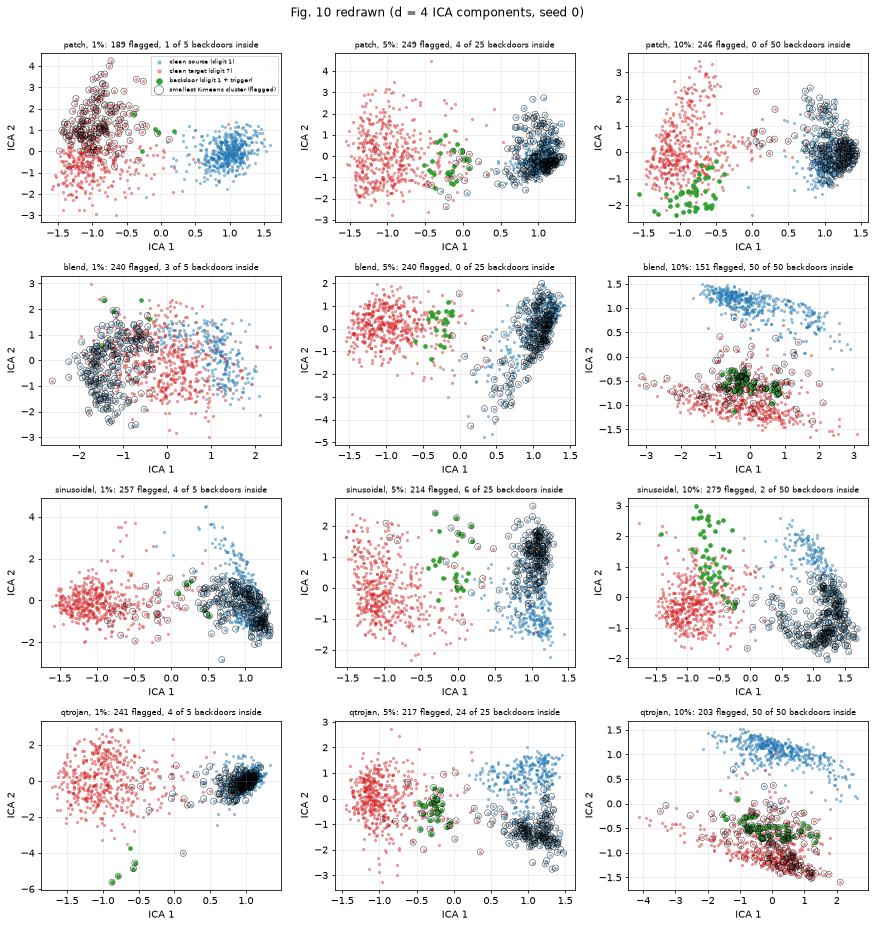

In [19]:
fig, axs = plt.subplots(len(ATTACKS), len(RATES), figsize=(4.2 * len(RATES), 3.3 * len(ATTACKS)), sharex=False)
for i, atk in enumerate(ATTACKS):
    for j, rate in enumerate(RATES):
        A, grp = PLOT[(atk, rate)]; V, km = ica_km(A, DSTAR["QSentry"], KMEANS_K, SEEDS[0]); ax = axs[i, j]
        sizes = np.bincount(km.labels_); fl = km.labels_ == sizes.argmin()
        for g in (0, 1, 2): ax.scatter(V[grp == g, 0], V[grp == g, 1], s=5 if g < 2 else 14, alpha=0.4 if g < 2 else 0.95, color=GC[g], label=GN[g] if (i == 0 and j == 0) else None)
        ax.scatter(V[fl, 0], V[fl, 1], s=40, facecolors="none", edgecolors="k", linewidths=0.4, label="smallest K-means cluster (flagged)" if (i == 0 and j == 0) else None)
        ax.set_title(f"{atk}, {rate:.0%}: {int(fl.sum())} flagged, {int((fl & (grp == 2)).sum())} of {int((grp == 2).sum())} backdoors inside", fontsize=8)
        ax.set_xlabel("ICA 1"); ax.set_ylabel("ICA 2")
axs[0, 0].legend(fontsize=6, markerscale=1.5, loc="best")
plt.suptitle(f"Fig. 10 redrawn (d = {DSTAR['QSentry']} ICA components, seed {SEEDS[0]})", y=1.0); plt.tight_layout(); plt.show()

## 7. Detection results: Table I (QSentry versus Raw)

Mean (and standard deviation over seeds, if more than one) of detection accuracy DA and F1 of the backdoor class on the **test** detection sets, at the validation-selected d. The paper's numbers are shown next to ours.

In [20]:
PAPER_T1 = {  # (QSentry DA, QSentry F1, Raw DA, Raw F1) in percent, Table I
    "patch":      {0.01: (99.8, 83.3, 98.4, 61.4), 0.05: (99.5, 90.9, 97.9, 70.3), 0.10: (99.7, 97.1, 97.8, 78.4)},
    "blend":      {0.01: (99.7, 76.9, 97.9, 64.1), 0.05: (99.4, 89.3, 98.4, 70.4), 0.10: (99.7, 97.1, 98.9, 79.1)},
    "sinusoidal": {0.01: (99.5, 71.4, 97.8, 62.7), 0.05: (98.9, 82.0, 96.7, 70.0), 0.10: (98.9, 90.1, 95.8, 78.9)},
    "qtrojan":    {0.01: (99.6, 71.4, 98.4, 62.3), 0.05: (98.8, 80.6, 96.1, 71.6), 0.10: (98.7, 88.5, 94.6, 78.1)}}
PAPER_T2_BD = {"patch": {0.01: 7, 0.05: 30, 0.10: 53}, "blend": {0.01: 8, 0.05: 31, 0.10: 53},
               "sinusoidal": {0.01: 9, 0.05: 36, 0.10: 61}, "qtrojan": {0.01: 9, 0.05: 37, 0.10: 63}}
PAPER_SIL = {  # (source, target, backdoor) silhouette read off Fig. 9 (the grouping of the extracted labels is inferred; see the text of Section V-D)
    "patch":      {0.01: (0.62, 0.60, 0.45), 0.05: (0.64, 0.62, 0.53), 0.10: (0.66, 0.64, 0.59)},
    "blend":      {0.01: (0.61, 0.59, 0.44), 0.05: (0.63, 0.61, 0.52), 0.10: (0.65, 0.63, 0.58)},
    "sinusoidal": {0.01: (0.60, 0.58, 0.38), 0.05: (0.62, 0.60, 0.47), 0.10: (0.64, 0.62, 0.54)},
    "qtrojan":    {0.01: (0.59, 0.57, 0.36), 0.05: (0.60, 0.58, 0.44), 0.10: (0.62, 0.60, 0.53)}}
PAPER_T3 = {  # F1 in percent: (MSPC, Distill to Detect, Q-Detection, QSentry), Table III
    "patch":      {0.01: (77.1, 77.8, 81.2, 83.3), 0.05: (85.9, 84.5, 88.5, 90.9), 0.10: (90.9, 90.2, 94.8, 97.1)},
    "blend":      {0.01: (73.9, 72.5, 74.8, 76.9), 0.05: (84.0, 83.7, 87.2, 89.3), 0.10: (93.7, 94.3, 95.6, 97.1)},
    "sinusoidal": {0.01: (68.9, 68.2, 69.1, 71.4), 0.05: (76.4, 75.8, 80.6, 82.0), 0.10: (85.0, 84.8, 88.5, 90.1)},
    "qtrojan":    {0.01: (67.6, 65.9, 69.8, 71.4), 0.05: (76.3, 75.6, 78.2, 80.6), 0.10: (83.1, 82.6, 86.9, 88.5)}}

test = DET[(DET.split == "test") & (DET.attack != "clean")]
def pick(name):
    t = test[test.detector == name]
    if name in DSTAR: t = t[t.d == DSTAR[name]]
    return t
def ms(t, col):
    g = t.groupby(["attack", "rate"])[col].agg(["mean", "std"]).fillna(0); return g
QS, RW = pick("QSentry"), pick("Raw")
rows = []
for atk in ATTACKS:
    for rate in RATES:
        p = PAPER_T1[atk][rate]
        q = QS[(QS.attack == atk) & (QS.rate == rate)]; w = RW[(RW.attack == atk) & (RW.rate == rate)]
        rows.append(dict(attack=atk, rate=f"{rate:.0%}",
                         QSentry_DA=f"{100 * q.DA.mean():.1f}", QSentry_DA_paper=p[0], QSentry_F1=f"{100 * q.F1.mean():.1f} +- {100 * q.F1.std(ddof=0):.1f}", QSentry_F1_paper=p[1],
                         Raw_DA=f"{100 * w.DA.mean():.1f}", Raw_DA_paper=p[2], Raw_F1=f"{100 * w.F1.mean():.1f} +- {100 * w.F1.std(ddof=0):.1f}", Raw_F1_paper=p[3]))
T1 = pd.DataFrame(rows); print(f"Table I, d(QSentry) = {DSTAR['QSentry']}, d(Raw) = {DSTAR['Raw']}, test detection sets, {len(SEEDS)} seed(s); DA and F1 in %"); print(T1.to_string(index=False))
mean_f1 = {rate: 100 * QS[QS.rate == rate].groupby("attack").F1.mean().mean() for rate in RATES}
print("\nmean F1 over the four attacks (abstract: 75.8 / 85.7 / 93.2 % at 1 / 5 / 10 %):", {f"{r:.0%}": round(v, 1) for r, v in mean_f1.items()})

Table I, d(QSentry) = 4, d(Raw) = 8, test detection sets, 3 seed(s); DA and F1 in %
    attack rate QSentry_DA  QSentry_DA_paper   QSentry_F1  QSentry_F1_paper Raw_DA  Raw_DA_paper       Raw_F1  Raw_F1_paper
     patch   1%       78.5              99.8   2.9 +- 1.3              83.3   78.9          98.4   1.6 +- 0.9          61.4
     patch   5%       75.0              99.5   1.8 +- 0.9              90.9   85.2          97.9 42.0 +- 41.3          70.3
     patch  10%       72.5              99.7   1.3 +- 1.3              97.1  100.0          97.8 100.0 +- 0.0          78.4
     blend   1%       75.6              99.7   2.1 +- 1.6              76.9   78.1          97.9   1.8 +- 0.8          64.1
     blend   5%       74.9              99.4   0.9 +- 1.3              89.3   76.9          98.4   6.7 +- 1.7          70.4
     blend  10%       76.5              99.7 16.8 +- 23.3              97.1   84.2          98.9 39.3 +- 43.0          79.1
sinusoidal   1%       76.9              99.5   1

### Table II: predicted versus actual cluster sizes, and Fig. 9: silhouette coefficients

Table II (mean over seeds): clusters of the QSentry K-means with K = 3, the smallest one is the backdoor cluster
    attack rate  actual_bd  pred_bd  delta  paper_pred_bd  paper_delta  actual_src  pred_src  actual_tgt  pred_tgt   TPR   FPR  AUROC
     patch   1%          5    216.3  211.3              7            2         495     377.7         500     406.0 0.667 0.214  0.814
     patch   5%         25    229.3  204.3             30            5         475     282.7         500     488.0 0.093 0.233  0.618
     patch  10%         50    228.0  178.0             53            3         450     286.7         500     485.3 0.033 0.238  0.521
     blend   1%          5    244.0  239.0              8            3         495     431.3         500     324.7 0.533 0.243  0.718
     blend   5%         25    227.7  202.7             31            6         475     280.7         500     491.7 0.040 0.232  0.563
     blend  10%         50    218.7  168.7             53            3         450 

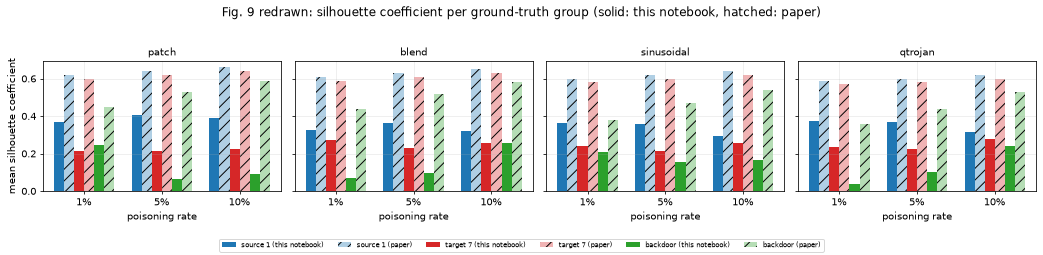

    attack  rate   src   tgt    bd  p_src  p_tgt  p_bd
     patch  0.01 0.368 0.213 0.249   0.62   0.60  0.45
     patch  0.05 0.406 0.213 0.067   0.64   0.62  0.53
     patch  0.10 0.390 0.224 0.091   0.66   0.64  0.59
     blend  0.01 0.327 0.270 0.068   0.61   0.59  0.44
     blend  0.05 0.363 0.228 0.098   0.63   0.61  0.52
     blend  0.10 0.319 0.258 0.258   0.65   0.63  0.58
sinusoidal  0.01 0.361 0.242 0.209   0.60   0.58  0.38
sinusoidal  0.05 0.357 0.216 0.156   0.62   0.60  0.47
sinusoidal  0.10 0.292 0.257 0.164   0.64   0.62  0.54
   qtrojan  0.01 0.376 0.234 0.037   0.59   0.57  0.36
   qtrojan  0.05 0.368 0.227 0.105   0.60   0.58  0.44
   qtrojan  0.10 0.317 0.277 0.242   0.62   0.60  0.53


In [21]:
rows = []
for atk in ATTACKS:
    for rate in RATES:
        q = QS[(QS.attack == atk) & (QS.rate == rate)]; nb = int(round(rate * N_DET))
        rows.append(dict(attack=atk, rate=f"{rate:.0%}", actual_bd=nb, pred_bd=round(q.pred_bd.mean(), 1), delta=round(q.pred_bd.mean() - nb, 1), paper_pred_bd=PAPER_T2_BD[atk][rate], paper_delta=PAPER_T2_BD[atk][rate] - nb,
                         actual_src=N_DET - nb, pred_src=round(q.pred_src.mean(), 1), actual_tgt=N_DET, pred_tgt=round(q.pred_tgt.mean(), 1),
                         TPR=round(q.TPR.mean(), 3), FPR=round(q.FPR.mean(), 3), AUROC=round(q.AUROC.mean(), 3)))
T2 = pd.DataFrame(rows); print("Table II (mean over seeds): clusters of the QSentry K-means with K = 3, the smallest one is the backdoor cluster"); print(T2.to_string(index=False))
sil_rows = []
for atk in ATTACKS:
    for rate in RATES:
        q = QS[(QS.attack == atk) & (QS.rate == rate)]; p = PAPER_SIL[atk][rate]
        sil_rows.append(dict(attack=atk, rate=rate, src=q.sil_src.mean(), tgt=q.sil_tgt.mean(), bd=q.sil_bd.mean(), p_src=p[0], p_tgt=p[1], p_bd=p[2]))
SIL = pd.DataFrame(sil_rows)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, atk in zip(axs, ATTACKS):
    g = SIL[SIL.attack == atk]; x = np.arange(len(RATES)); w = 0.13
    for k, (col, lab, c) in enumerate((("src", "source 1", "#1f77b4"), ("tgt", "target 7", "#d62728"), ("bd", "backdoor", "#2ca02c"))):
        ax.bar(x + (k - 1) * 2 * w - w / 2, g[col], w, color=c, label=f"{lab} (this notebook)")
        ax.bar(x + (k - 1) * 2 * w + w / 2, g["p_" + col], w, color=c, alpha=0.35, hatch="//", label=f"{lab} (paper)")
    ax.set_xticks(x); ax.set_xticklabels([f"{r:.0%}" for r in RATES]); ax.set_title(atk, fontsize=10); ax.set_xlabel("poisoning rate")
axs[0].set_ylabel("mean silhouette coefficient")
h_, l_ = axs[0].get_legend_handles_labels(); fig.legend(h_, l_, loc="lower center", ncol=6, fontsize=7)
plt.suptitle("Fig. 9 redrawn: silhouette coefficient per ground-truth group (solid: this notebook, hatched: paper)", y=1.03); plt.tight_layout(rect=[0, 0.08, 1, 1]); plt.show()
print(SIL.round(3).to_string(index=False))

### Sensitivity to the number of ICA components, and the other detectors on the same inputs

test F1 (mean over attacks and seeds) by number of ICA components d:
detector QSentry                  Raw              
rate        0.01   0.05   0.10   0.01   0.05   0.10
d                                                  
2.0        0.017  0.034  0.096  0.018  0.066  0.194
3.0        0.018  0.057  0.102  0.026  0.122  0.382
4.0        0.020  0.049  0.139  0.009  0.216  0.360
6.0        0.013  0.047  0.133  0.011  0.296  0.490
8.0        0.018  0.060  0.197  0.010  0.209  0.536



detectors compared on the same detection sets (mean over attacks and seeds):
                               AUROC                   F1                  FPR                  TPR                flagged                  
rate                              1%    10%     5%     1%    10%     5%     1%    10%     5%     1%    10%     5%       1%      10%       5%
detector                                                                                                                                    
QSentry                        0.690  0.646  0.630  0.020  0.139  0.049  0.232  0.227  0.228  0.500  0.357  0.247  233.333  233.667  228.417
QSentry-Ksil                     NaN    NaN    NaN  0.017  0.310  0.095  0.148  0.106  0.119  0.217  0.422  0.257  148.500  121.833  122.500
Raw                            0.552  0.816  0.679  0.010  0.536  0.209  0.226  0.105  0.182  0.217  0.595  0.383  226.083  129.333  187.333
ActClust                         NaN    NaN    NaN  0.006  0.014  0.014  0.4

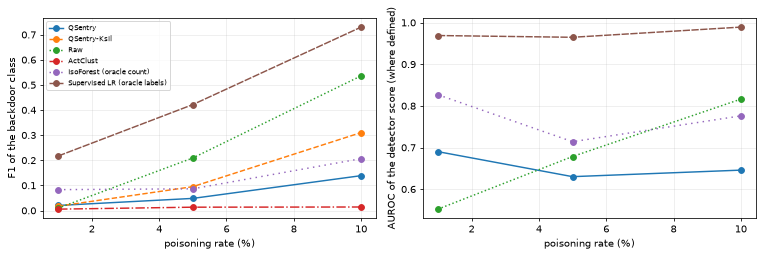


false alarm check: on a CLEAN model with NO backdoor the smallest K-means cluster still holds 19.2 % of the samples (mean silhouette of the 3 groups: 0.41 / 0.21). With backdoors the smallest cluster holds 23.2 % on average (true share: 0.5 / 2.5 / 5 % of the 1000 samples).


In [22]:
sens = test[test.detector.isin(["QSentry", "Raw"])].pivot_table(index="d", columns=["detector", "rate"], values="F1", aggfunc="mean")
print("test F1 (mean over attacks and seeds) by number of ICA components d:"); print(sens.round(3).to_string())
order = ["QSentry", "QSentry-Ksil", "Raw", "ActClust", "IsoForest (oracle count)", "Supervised LR (oracle labels)"]
rows = []
for name in order:
    t = pick(name)
    for rate in RATES:
        q = t[t.rate == rate]
        rows.append(dict(detector=name, rate=f"{rate:.0%}", F1=q.F1.mean(), TPR=q.TPR.mean(), FPR=q.FPR.mean(), AUROC=q.AUROC.mean(), flagged=q.n_flag.mean()))
OTH = pd.DataFrame(rows)
print("\ndetectors compared on the same detection sets (mean over attacks and seeds):"); print(OTH.pivot_table(index="detector", columns="rate", values=["F1", "TPR", "FPR", "AUROC", "flagged"]).reindex(order).round(3).to_string())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for name, ls in zip(order, ["-", "--", ":", "-.", (0, (1, 3)), (0, (5, 1))]):
    o = OTH[OTH.detector == name]; axs[0].plot([float(r[:-1]) for r in o.rate], o.F1, marker="o", ls=ls, label=name); axs[1].plot([float(r[:-1]) for r in o.rate], o.AUROC, marker="o", ls=ls, label=name)
axs[0].set_ylabel("F1 of the backdoor class"); axs[1].set_ylabel("AUROC of the detector score (where defined)")
for ax in axs: ax.set_xlabel("poisoning rate (%)")
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()
# the unsupervised K-means always returns a minority cluster, even for a clean model:
cl = DET[(DET.attack == "clean") & (DET.detector == "QSentry") & (DET.d == DSTAR["QSentry"]) & (DET.split == "test")]
print(f"\nfalse alarm check: on a CLEAN model with NO backdoor the smallest K-means cluster still holds {100 * cl.RCS.mean():.1f} % of the samples (mean silhouette of the 3 groups: {cl.sil_src.mean():.2f} / {cl.sil_tgt.mean():.2f}). "
      f"With backdoors the smallest cluster holds {100 * QS.RCS.mean():.1f} % on average (true share: 0.5 / 2.5 / 5 % of the 1000 samples).")

## 8. The paper's numbers next to ours, with a verdict per claim

Rules: a number is **reproduced** if it lies within 2 percentage points (accuracy-type metrics) or 0.02 (F1, silhouette: 0.05), **not reached** if ours is lower, **exceeded** if higher; claims without numbers are checked against an explicit threshold; claims about methods we did not implement are **cannot be checked**.

In [23]:
def verdict(ours, paper, tol):
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached")
V_ROWS = []
# Fig. 7/8: CA high
ca_min = bd.CA.min(); ca_mean = bd.CA.mean()
V_ROWS.append(("Figs. 7-8: CA of backdoored models stays high (axis starts at 0.86; no numbers)", "CA >= 0.86 everywhere", f"min CA {ca_min:.3f}, mean {ca_mean:.3f}", "reproduced" if ca_min >= 0.90 else "not reached"))
# ASR rises with rate and is high
asr_by_rate = bd.groupby("rate").ASR.mean(); mono = bool(np.all(np.diff(asr_by_rate.values) >= -0.02))
V_ROWS.append(("Figs. 7-8: ASR rises with the poisoning rate and ends high", "ASR high at 10 %, rising", "mean ASR " + ", ".join(f"{r:.0%}: {v:.2f}" for r, v in asr_by_rate.items()), "reproduced" if (mono and asr_by_rate.iloc[-1] >= 0.90) else "not reached"))
asr_cell = bd.groupby(["attack", "rate"]).ASR.mean()
V_ROWS.append(("Figs. 7-8: ASR high even at 1 % poisoning (Fig. 8 axis 0.86-1.0)", "ASR >= 0.86 at 1 %", "ASR at 1 %: " + ", ".join(f"{a} {asr_cell[(a, 0.01)]:.2f}" for a in ATTACKS), "reproduced" if all(asr_cell[(a, 0.01)] >= 0.86 for a in ATTACKS) else "not reached"))
# Table I
n_f1 = {"reproduced": 0, "exceeded": 0, "not reached": 0}; n_da = {"reproduced": 0, "exceeded": 0, "not reached": 0}; n_beat = 0; gaps = []
for atk in ATTACKS:
    for rate in RATES:
        p = PAPER_T1[atk][rate]; q = QS[(QS.attack == atk) & (QS.rate == rate)]; w = RW[(RW.attack == atk) & (RW.rate == rate)]
        n_f1[verdict(100 * q.F1.mean(), p[1], 2.0)] += 1; n_da[verdict(100 * q.DA.mean(), p[0], 2.0)] += 1; n_beat += int(q.F1.mean() > w.F1.mean()); gaps.append(100 * q.F1.mean() - p[1])
V_ROWS.append(("Table I: QSentry F1 per cell (12 cells)", "71.4-97.1 %", f"mean gap {np.mean(gaps):+.1f} points; cells: {n_f1}", "reproduced" if n_f1["reproduced"] + n_f1["exceeded"] == 12 else ("partly" if n_f1["reproduced"] + n_f1["exceeded"] > 0 else "not reached")))
V_ROWS.append(("Table I: QSentry DA per cell (12 cells)", "98.7-99.8 %", f"cells: {n_da}", "reproduced" if n_da["reproduced"] + n_da["exceeded"] == 12 else ("partly" if n_da["reproduced"] + n_da["exceeded"] > 0 else "not reached")))
for rate, ptxt in zip(RATES, (75.8, 85.7, 93.2)):
    V_ROWS.append((f"Abstract: mean F1 over the four attacks at {rate:.0%} poisoning", f"{ptxt} %", f"{mean_f1[rate]:.1f} %", verdict(mean_f1[rate], ptxt, 2.0)))
V_ROWS.append(("Table I: QSentry beats the Raw baseline in F1 (12 cells)", "12 of 12", f"{n_beat} of 12", "reproduced" if n_beat == 12 else ("partly" if n_beat > 0 else "not reached")))
# Table II
dl = [abs(r["delta"]) for r in T2.to_dict("records")]; pbd = [r["pred_bd"] / r["actual_bd"] for r in T2.to_dict("records")]
V_ROWS.append(("Table II: predicted backdoor cluster close to the true size (paper: |delta| <= 13 samples)", "|delta| <= 13, ratio 1.0-1.4", f"|delta| mean {np.mean(dl):.0f}, max {np.max(dl):.0f}; predicted/actual median {np.median(pbd):.1f}", "reproduced" if max(dl) <= 13 else "not reached"))
# Fig 9
low = int(sum(r.bd < min(r.src, r.tgt) for r in SIL.itertuples())); close = int(sum(abs(getattr(r, c) - getattr(r, "p_" + c)) <= 0.05 for r in SIL.itertuples() for c in ("src", "tgt", "bd")))
V_ROWS.append(("Fig. 9: backdoor silhouette is the lowest of the three groups (12 cells)", "12 of 12", f"{low} of 12", "reproduced" if low == 12 else ("partly" if low else "not reached")))
V_ROWS.append(("Fig. 9: silhouette values within 0.05 of the paper (36 values)", "see table", f"{close} of 36", "reproduced" if close >= 33 else ("partly" if close >= 12 else "not reached")))
rising = int(sum(SIL[SIL.attack == a].bd.is_monotonic_increasing for a in ATTACKS))
V_ROWS.append(("Fig. 9: backdoor silhouette increases with the poisoning rate (4 attacks)", "4 of 4", f"{rising} of 4", "reproduced" if rising == 4 else ("partly" if rising else "not reached")))
# Table III
t3 = {r: np.mean([PAPER_T3[a][r][k] for a in ATTACKS for k in range(3)]) for r in RATES}
V_ROWS.append(("Table III: QSentry beats MSPC, Distill-to-Detect, Q-Detection", "QSentry best in 12 of 12", "those methods are not re-implemented; classical stand-ins in section 7", "cannot be checked"))
VERD = pd.DataFrame(V_ROWS, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 110, "display.width", 250)
print(VERD.to_string(index=False))

                                                                                     claim                        paper                                                                     this notebook           verdict
           Figs. 7-8: CA of backdoored models stays high (axis starts at 0.86; no numbers)        CA >= 0.86 everywhere                                                          min CA 0.979, mean 0.985        reproduced
                                Figs. 7-8: ASR rises with the poisoning rate and ends high     ASR high at 10 %, rising                                            mean ASR 1%: 0.39, 5%: 0.91, 10%: 0.98        reproduced
                          Figs. 7-8: ASR high even at 1 % poisoning (Fig. 8 axis 0.86-1.0)           ASR >= 0.86 at 1 %                 ASR at 1 %: patch 0.18, blend 0.48, sinusoidal 0.02, qtrojan 0.87       not reached
                                                   Table I: QSentry F1 per cell (12 cells)                  71.4-97.1 % 

In [24]:
print(f"Total notebook run time: {(time.time() - T0_NOTEBOOK) / 60:.1f} min  (FAST_MODE = {FAST_MODE}, seeds {SEEDS}, N_TRAIN {N_TRAIN}, epochs {EPOCHS})")
print("Verdict counts:", VERD.verdict.value_counts().to_dict())

Total notebook run time: 42.9 min  (FAST_MODE = False, seeds [0, 1, 2], N_TRAIN 5000, epochs 5)
Verdict counts: {'not reached': 8, 'partly': 3, 'reproduced': 2, 'cannot be checked': 1}


## 9. Reading the paper critically

(All numbers below are from the executed `FAST_MODE = False` run in this file: 3 seeds, 5,000 training images per model; the printed tables above are the source.)

**What the experiments confirm.**
* The threat model is real. All four attacks implant a backdoor in the 8-qubit amplitude-encoded QNN while the clean accuracy stays at 0.98-0.99, the same as the clean model (0.986). With 5 % poisoning the attack success rate is 0.96-1.00 for patch, blend and QTrojan and 0.72 for the sinusoidal trigger; with 10 % it is 0.91-1.00 (section 4).
* The measurement matrix does carry the backdoor signature: a *supervised* logistic regression on the eight expectation values (it is given the labels, so it is not a defence) reaches an AUROC of 0.97-0.99 at all three poisoning rates and an F1 of 0.73 at 10 %. In the 2-D views (Figs. 4 and 10) the backdoor samples often form a visibly separate group, especially at 10 %.

**What does not hold up in our runs.**
* *The backdoor is weaker at 1 %.* With about 25 poisoned training images the attack success rate is 0.18 (patch), 0.48 (blend), 0.02 (sinusoidal) and 0.87 (QTrojan), whereas Fig. 8 of the paper suggests a high ASR at every rate. A random forest and an RBF-SVM trained on the same poisoned vectors learn the same backdoors almost perfectly even at 1 % (ASR 0.99-1.00, section 5): the 192-parameter QNN is the harder victim.
* *The detector does not isolate the backdoor.* The unsupervised recipe "ICA, K-means with K = 3, smallest cluster = backdoor" returns a smallest cluster of 216-248 samples (22-25 % of the detection set) at every poisoning rate, against a true backdoor group of 5, 25 or 50 samples. Most of the flagged samples are clean (FPR about 23 %), so DA is 72-79 % instead of 98.7-99.8 %, the mean F1 over the four attacks is 2.0 / 4.9 / 13.9 % instead of 75.8 / 85.7 / 93.2 %, and Table II is missed by a factor of about 9 (predicted 216-248 against 5/25/50). In Fig. 10 the flagged cluster is typically a part of the clean source class (digits 1 are written upright, slanted or with a foot, so the clean classes are not single compact blobs) and only sometimes contains the backdoor samples. Choosing K by the silhouette (`QSentry-Ksil`) helps a little at 10 % (F1 0.31) and not at all at 1 %.
* *A model with no backdoor gets the same answer.* On a clean model the smallest K-means cluster still holds 19 % of the samples, so the cluster size alone cannot signal an attack; the paper's rule "detection is triggered when all preset separation metrics exceed their thresholds" is not specified well enough to implement.
* *QSentry does not beat the Raw baseline here.* It wins in 5 of 12 cells of Table I. At 10 % poisoning the pixel-domain baseline reaches a mean F1 of 0.54 against 0.14 for QSentry, but with standard deviations of up to 47 points over the three seeds in the other cells (the K-means either finds the trigger group or it does not), and for the QTrojan attack our "Raw" input is the post-trigger amplitude vector, which sees the large trigger directly.
* *Silhouettes are lower than in Fig. 9.* The clean groups reach 0.2-0.4 instead of 0.57-0.66, the backdoor group is the lowest in 11 of 12 cells but does not rise consistently with the poisoning rate (2 of 4 attacks).

**Possible reasons for the gap (we cannot tell which applies).**
* Unspecified details matter: trigger strength, training length, the logit scale, whether the ICA output is whitened (our `FastICA` gives every component unit variance, so the class axis <Z0>, <Z1> counts as one of d equal directions, which favours splitting a clean class into sub-modes), the number d of components, and the composition of the detection set. We selected d on held-out validation sets; the test F1 of the QSentry pipeline is low for every d (section 7).
* The numbers in Tables I and II (predicted cluster sizes within +2 to +13 samples of the truth, source and target clusters of 495 and 498 samples, silhouettes of 0.57-0.66 for real MNIST digits in an 8-d measurement space) are much more regular than a K-means on real handwritten digits normally allows, and no standard deviation over the 3-5 repetitions is reported.
* Eq. 13 adds a total-variation term meant to *hide* anomalous measurement distributions from the defender, which should make detection harder, yet the reported detection is excellent; the interplay is not discussed. We trained without that term.
* The paper's Raw baseline is vague (what is clustered, with which K?), the three methods of Table III come without code or settings, and MSPC rescales pixel values, which an amplitude encoding (it normalises its input) removes by construction.

**Other limits.** Binary task, 8 qubits, exact (shot-noise-free) expectation values; the authors themselves note the large number of measurement samples needed on real hardware. The defender is assumed to know the number of clusters (K = 3 presupposes that source, target and backdoor samples are all present in a given mixture); the activation-clustering family usually works per predicted class instead. An adaptive attacker who keeps the measurement statistics of triggered inputs close to the clean ones would defeat the method (acknowledged in the conclusion).

## 10. Exercises

1. **Rate sweep.** Add the rates 2 %, 3 % and 20 % to `RATES`. Where does the smallest cluster start to coincide with the backdoor group? Plot RCS against the true rate.
2. **Choose K properly.** The `QSentry-Ksil` variant picks K by the silhouette. Replace the "smallest cluster" rule by "the cluster with the smallest *within-cluster spread*" (the backdoor group is compact) and compare F1 and FPR.
3. **Per-class clustering.** Implement the classic activation-clustering protocol: take only the inputs the model *predicts* as 7, cluster those into two groups and flag the smaller one. How does it compare with the 3-cluster version, and what does it need to know?
4. **Trigger strength.** Change `SIN_AMP` (0.2 in the paper) to 0.3 and 0.5, or the patch size `PATCH` to 2 and 5. Plot ASR and detection F1 against the trigger strength: is a weak backdoor harder to implant or harder to detect?
5. **Shot noise.** Replace the exact expectation values by estimates from 100, 1000 and 10000 shots per input (sample the measurement outcomes of the 8 qubits) and measure how fast the clustering degrades. This is the cost of QSentry on real hardware that the paper mentions but does not quantify.